[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/24_Poisoning_Attacks_Against_QML/RDQKL_DecentralizedKernelLearning_Ma2025.ipynb)

# RDQKL for noisy and adversarial decentralised quantum kernel learning: Ma et al. (2025) step by step

**Paper.** Wenxuan Ma, Kuan-Cheng Chen, Shang Yu, Mengxiang Liu and Ruilong Deng, *"RDQKL: Robust Decentralized Quantum Kernel Learning for Noisy and Adversarial Environment"*, IEEE International Conference on Quantum Computing and Engineering (QCE) 2025, DOI [10.1109/QCE65121.2025.00238](https://doi.org/10.1109/qce65121.2025.00238), arXiv [2504.13782](https://arxiv.org/abs/2504.13782).

**What this notebook does.** Several quantum computing units (QUs) each hold a private part of a dataset and want to learn one good *quantum kernel* together, without a central server. Each unit trains the parameters of a noisy 5-qubit feature-map circuit by **kernel-target alignment** on its local data, then exchanges parameters with its neighbours (**gossip averaging**). Two things can go wrong: some units have a much **noisier quantum computer** (depolarising noise), and some units may be **malicious** (they send Gaussian garbage or the sign-flipped average, i.e. a *poisoning* of the shared model). The paper proposes **RDQKL**: a clipping aggregation rule that bounds how much a received parameter vector can move a unit. The notebook re-implements the whole pipeline, reproduces the paper's Tables I and II as far as the information in the paper allows, and compares every number with the paper's.

**How to run.** Open in Google Colab (or locally), CPU runtime, *Runtime -> Run all*. With `FAST_MODE = True` (default, a few minutes) every experiment runs with tiny budgets, which only demonstrates that the code works; set `FAST_MODE = False` in the configuration cell for the budgets used to report results (about 40 minutes on 4 CPU cores; the Colab free tier has 2 cores, set `N_WORKERS = 2`, about 80 minutes). Nothing needs to be downloaded by hand: Dataset 1 is generated, Dataset 2 (MNIST) comes from a public Hugging Face mirror.

**What you get at the end.** The circuit that is simulated, drawn from the real PennyLane QNode, with the fast training simulator asserted equal to it; Tables I and II of the paper re-computed next to the paper's numbers with a verdict for every claim; the effect of noise on the kernel, on the gradient and on the learning curve (Fig. 3 analogue); and an honest discussion of what could and could not be reproduced.

## The paper in one page

**Problem.** Quantum kernel learning (QKL) trains a parametrised feature-map circuit so that the kernel $K(x,x')=|\langle\phi(x)|\phi(x')\rangle|^2$ separates the classes. In a *decentralised* network every unit has only local data, noise differs from unit to unit, and some units may behave adversarially. The security angle (our topic folder is *poisoning attacks against QML*): a malicious unit poisons the shared parameters through the messages it sends.

**Method.**
- *Feature map (Fig. 2).* 5 qubits, 8 layers; each layer = Hadamards, `RZ(x_i)` data embedding (x1 on qubits 1, 3, 5 and x2 on qubits 2, 4), `RY(theta)` per qubit, a ring of CNOTs, `RZ(theta')` per qubit. A depolarising channel $\mathcal N_{\tilde p}(\rho)=(1-\tilde p)\rho+\tilde p\,I/D$ follows every gate.
- *Kernel.* $K(x,x')=\mathrm{Tr}[P_0\,U(x')^\dagger U(x)\,\rho_0\,U(x)^\dagger U(x')]$, i.e. the probability of measuring all zeros after running $U(x)$ and then $U(x')^\dagger$. Noise shrinks it towards $1/D$ (Eq. 14).
- *Training objective.* Kernel-target alignment $A=\sum_{ij}y_iy_jK_{ij}/(n\sqrt{\sum_{ij}K_{ij}^2})$ (Eq. 18), loss $-A$, gradient descent with step $\eta$ on a random mini-batch of $q_i$ local samples (Eqs. 19, 23, 24).
- *Algorithm 1 (decentralised QKL).* Each unit: local gradient step, send its parameters to its neighbours, aggregate $\theta_i\leftarrow\sum_j w_{ij}\theta_j$ with a doubly stochastic $W$ (Eq. 26). The network-average parameters then follow SGD on the global loss (Eq. 30) and all units reach consensus (Eq. 32), even if some are very noisy, because a very noisy unit has a vanishing gradient (Eq. 21).
- *Attacks (Eqs. 33-34).* A malicious unit sends either a Gaussian vector with the mean and variance of what it received, or the **negative average** of what it received (sign flipping).
- *Defence RDQKL (Eqs. 35-36).* Aggregate with a **clipped** rule $\sum_j w_{ij}\,\mathrm{Clip}(\theta_j,\tau)$, $\mathrm{Clip}(v,\tau)=\min(1,\tau/\|v\|)\,v$; the unit's own parameters are the trusted reference. $\tau=0.5$ (Gaussian) and $0.05$ (sign flipping).

**Data (Figs. 4 and 5).** *Dataset 1:* a 4x4 checkerboard on the unit square with Gaussian blobs, split **heterogeneously** over 4 units on a **ring** (each unit sees one quadrant). *Dataset 2:* MNIST digits 7 and 9, reduced by an autoencoder (4 fully connected layers each side) to a 2-D latent in the unit square, split **randomly** over 4 units on a **fully connected** network. Unit 2 is the noisy or malicious one. Simulator: PennyLane `default.mixed`, backprop.

**Metrics.** *Iteration times* (convergence speed), *Score1* (train local / test local), *Score2* (train local / test on the whole test set), *Score3* (train and test on everything), see Tables I and II.

**Claims we can test.**

| Id | Claim | Where |
|---|---|---|
| C1 | Strong noise slows kernel learning, moderate noise does not | Fig. 3, Eq. 21 |
| C2 | Decentralised QKL needs 3-4x fewer iterations than centralised QKL | Tables I, II |
| C3 | Decentralised accuracy (Score3) is comparable to centralised and better than purely local training | Tables I, II |
| C4 | A unit with 0.5 % / 5 % noise does not hurt the other units | Tables I, II |
| C5 | Gaussian attack ruins plain decentralised QKL (Score3 about 50 %), RDQKL repairs it (97.8 % / 85.0 %) | Tables I, II |
| C6 | Sign flipping hurts plain decentralised QKL, the clip mitigates it (88.9 % / 83.9 %) | Tables I, II |

## What follows the paper and what had to be chosen

The paper is a short conference paper: several details are not given. Every choice below is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Circuit | Fig. 2 (superposition, embedding, RY + ring + RZ), 8 layers, 5 qubits | same; per layer H, RZ(x), RY, ring of 5 CNOTs, RZ; **80 trainable angles** (8 layers x 2 x 5); the order RY, ring, RZ inside the trainable layer is read from the figure |
| Noise | depolarising after every gate, `default.mixed` | channel after every gate on every qubit the gate touches (a CNOT is followed by two channels); simulated **exactly** with a Pauli-transfer-matrix simulator asserted equal to the `default.mixed` QNode |
| Kernel circuit | $U(x')^\dagger U(x)$ and a projector on $|0\rangle^{\otimes n}$ | same; the noisy kernel is evaluated with the Heisenberg picture, which is exact |
| Dataset 1 size / spread | checkerboard of 16 cells, Gaussian blobs; sizes not given | 15 points per cell with sigma = 0.05 (240 points, 180 train / 60 test); quadrant split into 4 units |
| Dataset 2 | MNIST 7/9, autoencoder to 2-D | 240 test-split images (120 per digit); autoencoder 784-400-100-25-2 trained on 6000 train-split 7/9 images, latent min-max scaled to [0, 1]; random split into 4 units |
| Step size, batch | not given | $\eta=4$, $q_i=8$, identical initial angles (uniform in $[-\pi,\pi]$) on all units |
| Aggregation weights | doubly stochastic $W$ | Metropolis weights of the ring / complete graph |
| Clipping | Eq. 36 clips $\theta_j$ itself | the literal rule would pull all 80 angles towards a ball of radius $\tau$ around the origin, so we clip the **difference to the unit's own parameters** (centred clipping, same intent: "local data is the trusted reference") |
| Gaussian attack | mean and variance of the received parameters | mean per coordinate, variance pooled over all received entries |
| Classifier on the kernel | not stated | `SVC(kernel="precomputed", C=10)`, evaluated with the unit's own noisy kernel |
| "Iteration times" | to termination | first iteration at which the honest units' alignment on 64 fixed training points covers 50 % of the gain of the normal-noise decentralised run |
| Score definitions | Score1/2/3 as in Section V-A | same: local/local, local/whole, whole/whole; averaged over the honest units (paper footnotes) |
| Seeds | not stated | one seed (42) by default, configurable |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib, pillow and PyTorch.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1" huggingface_hub pyarrow
if importlib.util.find_spec("torch") is None:           # preinstalled on Colab
    %pip install -q torch --index-url https://download.pytorch.org/whl/cpu
print("setup done (if Colab asks you to restart the session, do so and run all cells again)")

setup done (if Colab asks you to restart the session, do so and run all cells again)


In [2]:
# Hugging Face token: MNIST is public, so no token is needed here. The code still resolves a token (if you have one) in the
# safe way: from the environment or from Colab Secrets (Settings > Secrets > HF_TOKEN). Never type a token into a cell.
import os
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None
print("Hugging Face token available:", HF_TOKEN is not None, "(not needed for the public MNIST mirror used here)")

Hugging Face token available: True (not needed for the public MNIST mirror used here)


In [3]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE = False             # True: class demo (about 12 min, tiny budgets, numbers NOT meaningful); False: the full budgets below (about 40 min on 4 CPU cores)
SEED      = 42
SEEDS     = [42]              # CHOICE: one seed (CPU budget); [42, 43, 44] gives mean +/- std in the tables but takes 3x longer

# --- quantum kernel circuit (paper Fig. 2, Section V-A) ---
N_QUBITS  = 5                 # paper: 5 working qubits
N_LAYERS  = 8                 # paper: a stack of 8 layers of the Fig. 2 circuit (80 trainable angles)
P_NORMAL  = 0.0005            # paper: depolarising probability 0.05 % after every gate in the normal case
P_REL_HIGH_DS1, P_REL_HIGH_DS2 = 0.005, 0.002     # paper: 0.5 % (Dataset 1) / 0.2 % (Dataset 2) on node 2
P_QUITE_HIGH = 0.05           # paper: 5 % on node 2

# --- decentralised learning (Algorithm 1) ---
N_NODES   = 4
LR        = 4.0               # CHOICE: step size eta (paper does not give it); tuned once on the training data of Dataset 1
Q_BATCH   = 8                 # CHOICE: samples per local stochastic gradient q_i (paper does not give it)
TAU_GAUSS, TAU_SIGN = 0.5, 0.05   # paper: clipping thresholds tau for the Gaussian / sign-flipping attack
ATTACKER  = 1                 # paper: "node 2" (index 1) is the high-noise / malicious node
SVM_C     = 10.0              # CHOICE: C of the SVM that sits on top of the learned kernel
ALIGN_FRAC = 0.5              # CHOICE: "iteration times" = first iteration at which the honest units' training-set alignment has covered
                              #         this fraction of the gain reached by the normal-noise decentralised run

# --- budgets: iterations of the decentralised runs; the centralised run gets CEN_FACTOR times more (paper: about 3-4x) ---
DS1_ITERS   = 20  if FAST_MODE else 300      # paper: Table I, 1050 (decentralised) / 3900 (centralised) iterations
DS2_ITERS   = 20  if FAST_MODE else 250      # paper: Table II, 270 / 800 iterations
CEN_FACTOR  = 3
SWEEP_ITERS = 30  if FAST_MODE else 200      # Fig. 3 analogue: single unit, several noise levels
SWEEP_P     = [0.0, 0.001, 0.01, 0.05] if FAST_MODE else [0.0, 0.0005, 0.001, 0.002, 0.005, 0.01, 0.05]
EVAL_POINTS = 64              # training points on which the kernel-target alignment is tracked
N_WORKERS   = 3 if FAST_MODE else 4          # parallel worker processes (one experiment each); Colab free tier has 2 CPUs: set 2

# --- data ---
PER_CELL, SIGMA, TEST_SIZE = 15, 0.05, 0.25  # Dataset 1: 16 checkerboard cells x 15 points; CHOICE: sigma = 0.05 (paper: "Gaussian random data")
DIGITS      = (7, 9)                          # Dataset 2: MNIST digits 7 and 9
N_PER_CLASS = 120                             # CHOICE: 240 images -> 180 train / 60 test (the paper's accuracies are multiples of 1/60)
AE_TRAIN_IMAGES, AE_EPOCHS = (3000, 25) if FAST_MODE else (6000, 60)   # CHOICE: autoencoder (4 FC layers each side) trained on 7/9 images of the MNIST train split
DATA_DIR    = "rdqkl_data"                    # downloads / module file are cached here (current working directory)
IBM_TOKEN   = ""                              # not used: depolarising noise is simulated, no real hardware needed
print("FAST_MODE =", FAST_MODE, "| DS1/DS2 iterations:", DS1_ITERS, DS2_ITERS, "| workers:", N_WORKERS)

FAST_MODE = False | DS1/DS2 iterations: 300 250 | workers: 4


In [4]:
import os, sys, io, time, math, random, warnings
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
import sklearn
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
warnings.filterwarnings("ignore")
os.makedirs(DATA_DIR, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})
print("numpy", np.__version__, "| torch", torch.__version__, "| scikit-learn", sklearn.__version__)

numpy 2.5.4 | torch 2.14.1+cpu | scikit-learn 1.9.1


## 1. The noisy quantum kernel, simulated exactly and fast

Training needs the kernel and its gradient for hundreds of mini-batches and four units, each of them through 8 layers of noisy gates. A density-matrix simulator for 5 qubits (a 32x32 matrix) is exact but slow in a gradient loop. We use the **Pauli-transfer-matrix** picture instead: a density matrix is the real vector of its 4^5 = 1024 Pauli coefficients $r_P=\mathrm{Tr}[P\rho]$. In this picture

- a single-qubit rotation is a 3x3 rotation of the $(X,Y,Z)$ components of that qubit,
- a Hadamard swaps $X\leftrightarrow Z$ and flips $Y$,
- a CNOT is a signed permutation of the Pauli strings,
- a depolarising channel multiplies every coefficient whose Pauli string acts non-trivially on the qubit by $1-4\tilde p/3$.

Everything is real, exact (no approximation of the noise) and differentiable with PyTorch autograd. The noisy kernel of Eq. (5) is evaluated without ever forming the pair circuit: $K(x,x')=\mathrm{Tr}[P_0\,\Psi_{x'}(\rho_x)]$ equals the overlap between the forward state $\rho_x$ and the *Heisenberg-evolved* projector $\Psi_{x'}^\dagger(P_0)$ (noise placed before every gate, same gate order). That turns an n x n kernel into 2n circuit runs. The next cell writes the simulator and the training functions into a module file, `rdqkl_core.py`, so that worker processes can import it (the experiments run in parallel).

In [5]:
%%writefile rdqkl_core.py
# rdqkl_core.py: exact simulator of the noisy 5-qubit kernel circuit + decentralised QKL / RDQKL training (see the markdown above)
import numpy as np, torch, time
from sklearn.svm import SVC
torch.set_num_threads(1)
import math
N=5; D=4**N
RING=[(i,(i+1)%N) for i in range(N)]
def feat_qubit(i): return i%2          # CHOICE: x1 on qubits 1,3,5 and x2 on qubits 2,4 (1-based), as in the paper
_PAULI=[np.eye(2),np.array([[0,1],[1,0]]),np.array([[0,-1j],[1j,0]]),np.diag([1,-1])]
_DIG=np.array([[(i//4**(N-1-q))%4 for q in range(N)] for i in range(D)])
def _cnot_tables(c,t):
    C2=np.array([[1,0,0,0],[0,1,0,0],[0,0,0,1],[0,0,1,0]],dtype=complex)
    two={}
    for a in range(4):
        for b in range(4):
            M=C2@np.kron(_PAULI[a],_PAULI[b])@C2.conj().T
            for a2 in range(4):
                for b2 in range(4):
                    ov=np.trace(np.kron(_PAULI[a2],_PAULI[b2]).conj().T@M)/4
                    if abs(ov)>0.5: two[(a,b)]=(a2,b2,int(round(ov.real)))
    perm=np.zeros(D,dtype=np.int64); sign=np.ones(D)
    for idx in range(D):
        d=list(_DIG[idx]); a2,b2,s=two[(d[c],d[t])]
        d[c]=a2; d[t]=b2
        perm[idx]=sum(v*4**(N-1-q) for q,v in enumerate(d)); sign[idx]=s
    return perm,sign
_CT={c:_cnot_tables(c,t) for c,t in RING}
def _ring_tables(noise_before):
    idx=np.arange(D); sign=np.ones(D); expo=np.zeros(D)
    for c,t in RING:
        perm,sg=_CT[c]; e=(_DIG[:,c]!=0).astype(float)+(_DIG[:,t]!=0)
        sign=sg*sign[perm]; expo=(e[perm] if noise_before else e)+expo[perm]; idx=idx[perm]
    return torch.tensor(idx),torch.tensor(sign),torch.tensor(expo)
RING_TAB={nb:_ring_tables(nb) for nb in (False,True)}
def _rz_mat(a):
    c,s=torch.cos(a),torch.sin(a); o=torch.ones_like(a); z=torch.zeros_like(a)
    return torch.stack([o,z,z,z, z,c,-s,z, z,s,c,z, z,z,z,o],-1).reshape(*a.shape,4,4)
def _ry_mat(a):
    c,s=torch.cos(a),torch.sin(a); o=torch.ones_like(a); z=torch.zeros_like(a)
    return torch.stack([o,z,z,z, z,c,z,s, z,z,o,z, z,-s,z,c],-1).reshape(*a.shape,4,4)
_H=torch.zeros(4,4,dtype=torch.float64); _H[0,0]=1; _H[1,3]=1; _H[3,1]=1; _H[2,2]=-1
def apply_q(s,M,q):
    B=s.shape[0]; A=4**q; C=4**(N-q-1)
    v=s.reshape(B,A,4,C).permute(0,2,1,3).reshape(B,4,A*C)
    return torch.bmm(M,v).reshape(B,4,A,C).permute(0,2,1,3).reshape(B,D)
def layer_matrices(x,theta,L,f,noise_before):
    B=x.shape[0]
    ones=torch.ones_like(f); Dq=torch.diag_embed(torch.stack([ones,f,f,f],-1))      # (B,4,4)
    def wrap(M):
        d=Dq.reshape(B,*([1]*(M.dim()-3 if M.dim()>2 else 0)),4,4)
        if M.dim()==2: M=M.expand(B,4,4); d=Dq
        return M@d if noise_before else d@M
    xq=x[:,[feat_qubit(q) for q in range(N)]]
    Ah=wrap(_H).unsqueeze(1); Arx=wrap(_rz_mat(xq))
    Ary=wrap(_ry_mat(theta[:,:,0,:])); Arz=wrap(_rz_mat(theta[:,:,1,:]))
    base=(Arx@Ah).unsqueeze(1)
    first=Ary[:,:1]@base
    rest=Ary[:,1:]@base@Arz[:,:-1]
    return torch.cat([first,rest],1), Arz[:,-1]
def evolve(s,x,theta,L,p,noise_before=False):
    """Pauli-transfer-matrix simulation of the noisy feature-map circuit (exact). s (B,1024) coefficients Tr[P rho];
    theta (B,L,2,N) or (L,2,N); x (B,2); p scalar or (B,) depolarising probability after (before) every gate."""
    B=s.shape[0]
    if theta.dim()==3: theta=theta.unsqueeze(0).expand(B,-1,-1,-1)
    p=torch.as_tensor(p,dtype=torch.float64).expand(B); f=1-4*p/3
    Ml,Mfin=layer_matrices(x,theta,L,f,noise_before)
    idx,sign,expo=RING_TAB[noise_before]
    mask=sign.unsqueeze(0)*f.unsqueeze(1)**expo.unsqueeze(0)
    for l in range(L):
        for q in range(N): s=apply_q(s,Ml[:,l,q],q)
        s=s[:,idx]*mask
    for q in range(N): s=apply_q(s,Mfin[:,q],q)
    return s
_ZI=torch.tensor(np.all(np.isin(_DIG,[0,3]),axis=1).astype(float))
def zero_state(B): return _ZI.expand(B,-1).clone()
def kernel_matrix(XA,XB,theta,L,p):
    r=evolve(zero_state(len(XA)),XA,theta,L,p)
    o=evolve(zero_state(len(XB)),XB,theta,L,p,noise_before=True)
    return r@o.T/2**N
def kernel_blocks(X,theta,L,p,nb,q):
    """X (nb*q,2); theta (nb,L,2,N); p (nb,) -> K (nb,q,q): kernel inside each node's block"""
    th=theta.repeat_interleave(q,0); pp=torch.as_tensor(p,dtype=torch.float64).repeat_interleave(q)
    r=evolve(zero_state(len(X)),X,th,L,pp); o=evolve(zero_state(len(X)),X,th,L,pp,noise_before=True)
    return torch.bmm(r.reshape(nb,q,D),o.reshape(nb,q,D).transpose(1,2))/2**N
def alignment(K,y):
    """Eq. (18): sum_ij y_i y_j K_ij / (n sqrt(sum K_ij^2)); K (...,n,n), y (...,n)"""
    Y=y.unsqueeze(-1)*y.unsqueeze(-2); n=K.shape[-1]
    return (Y*K).sum((-1,-2))/(n*torch.sqrt((K*K).sum((-1,-2))))

# ----------------------------------------------------------------------------------------------
# Decentralised quantum kernel learning (Algorithm 1) and its robust variant RDQKL
# ----------------------------------------------------------------------------------------------
def metropolis(adj):
    """Doubly stochastic Metropolis-Hastings weight matrix W of an undirected graph (Eq. 26)"""
    n=len(adj); W=np.zeros((n,n)); deg=adj.sum(1)
    for i in range(n):
        for j in range(n):
            if i!=j and adj[i,j]: W[i,j]=1/(1+max(deg[i],deg[j]))
        W[i,i]=1-W[i].sum()
    return W
def ring_adj(n=4):
    a=np.zeros((n,n),int)
    for i in range(n): a[i,(i+1)%n]=a[(i+1)%n,i]=1
    return a
def full_adj(n=4): return np.ones((n,n),int)-np.eye(n,dtype=int)

def clip_to(v,tau):
    """Eq. (35): min(1, tau/||v||) * v"""
    nrm=torch.linalg.norm(v,dim=-1,keepdim=True)
    return v*torch.clamp(tau/(nrm+1e-12),max=1.0)

def run_dqkl(nodes_X,nodes_y,W,p_nodes,L,iters,lr,q,seed,attack=None,attacker=None,aggregator="mean",tau=None,
             eval_X=None,eval_y=None,eval_every=50):
    """Algorithm 1. nodes_X[i] (n_i,2): local training data of unit i; nodes_y in {0,1}; W doubly stochastic (n,n);
    p_nodes[i]: depolarising probability of unit i; attack in {None,'gaussian','signflip'} played by unit `attacker`;
    aggregator 'mean' (Eq. 26), 'clip' (RDQKL, centred clipping, Eq. 36) or 'median' (coordinate-wise median baseline)."""
    n=len(nodes_X); g=torch.Generator().manual_seed(seed); rng=np.random.default_rng(seed)
    theta0=torch.rand(L,2,N,generator=g,dtype=torch.float64)*2*np.pi-np.pi          # CHOICE: uniform in [-pi, pi]
    theta=theta0.unsqueeze(0).repeat(n,1,1,1).clone()                                # same initial parameters everywhere
    Wt=torch.tensor(W,dtype=torch.float64)
    Xt=[torch.tensor(a) for a in nodes_X]; yt=[torch.tensor(2.0*np.asarray(b)-1) for b in nodes_y]
    p=torch.as_tensor(p_nodes,dtype=torch.float64)
    honest=[i for i in range(n) if i!=attacker]; hist=[]
    for k in range(iters+1):
        if eval_X is not None and k%eval_every==0:
            with torch.no_grad():
                Ke=kernel_blocks(eval_X.repeat(n,1),theta,L,p,n,len(eval_X))
                hist.append((k,alignment(Ke,eval_y.repeat(n,1)).numpy().copy()))
        if k==iters: break
        idx=[rng.choice(len(Xt[i]),min(q,len(Xt[i])),replace=False) for i in range(n)]       # stochastic gradient, q_i samples (Eq. 24)
        Xb=torch.cat([Xt[i][idx[i]] for i in range(n)]); yb=torch.stack([yt[i][idx[i]] for i in range(n)])
        th=theta.clone().requires_grad_(True)
        loss=-alignment(kernel_blocks(Xb,th,L,p,n,min(q,len(Xt[0]))),yb)[honest].sum()       # Eq. (19)/(22)
        loss.backward()
        half=(theta-lr*th.grad).reshape(n,-1)                                         # Eq. (23)
        sent=half.clone()                                                             # what the neighbours receive
        if attacker is not None:
            nb=[j for j in range(n) if W[attacker,j]>0 and j!=attacker]; M=half[nb]
            if attack=="gaussian":   # Eq. (33); CHOICE: mean per coordinate, variance pooled over all received entries
                sent[attacker]=M.mean(0)+M.var().sqrt()*torch.randn(M.shape[1],generator=g,dtype=torch.float64)
            elif attack=="signflip": sent[attacker]=-M.mean(0)                         # Eq. (34)
        new=half.clone()
        for i in honest:
            nbrs=[j for j in range(n) if Wt[i,j]>0]
            if aggregator=="mean":
                new[i]=(Wt[i].unsqueeze(1)*sent).sum(0)                               # Eq. (26)
            elif aggregator=="clip":   # Eq. (36). CHOICE: the clip acts on the *difference to the own (trusted) parameters*
                new[i]=half[i]+(Wt[i].unsqueeze(1)*clip_to(sent-half[i],tau)).sum(0)
            elif aggregator=="median":
                stack=torch.stack([half[i] if j==i else sent[j] for j in nbrs]); new[i]=stack.median(0).values
        theta=new.reshape_as(theta).detach()
    return theta,hist

def svm_accuracy(theta_i,p_i,L,Xtr,ytr,Xte,yte,C=10.0):
    """SVM on the precomputed noisy quantum kernel of one unit (its own parameters theta_i and noise p_i)"""
    Xtr=torch.tensor(Xtr); Xte=torch.tensor(Xte)
    with torch.no_grad():
        Ktr=kernel_matrix(Xtr,Xtr,theta_i,L,p_i).numpy(); Kte=kernel_matrix(Xte,Xtr,theta_i,L,p_i).numpy()
    clf=SVC(kernel="precomputed",C=C).fit((Ktr+Ktr.T)/2,ytr)
    return float(clf.score(Kte,yte))

def run_job(spec):
    """One experiment (picklable, so that it can run in a worker process): train, then compute Score1/2/3 per unit."""
    t0=time.time(); torch.set_num_threads(1)
    d=spec["data"]; L=spec["L"]; n=len(spec["nodes_X"])
    theta,hist=run_dqkl(spec["nodes_X"],spec["nodes_y"],spec["W"],spec["p_nodes"],L,spec["iters"],spec["lr"],spec["q"],spec["seed"],
                        attack=spec.get("attack"),attacker=spec.get("attacker"),aggregator=spec.get("aggregator","mean"),tau=spec.get("tau"),
                        eval_X=torch.tensor(d["eval_X"]),eval_y=torch.tensor(2.0*d["eval_y"]-1),eval_every=spec["eval_every"])
    scores=[]
    for i in range(n):
        if i==spec.get("attacker"): scores.append((np.nan,np.nan,np.nan)); continue
        p_i=spec["p_nodes"][i]
        s3=svm_accuracy(theta[i],p_i,L,d["Xtr"],d["ytr"],d["Xte"],d["yte"])
        if spec["mode"]=="central": scores.append((np.nan,np.nan,s3)); continue
        s1=svm_accuracy(theta[i],p_i,L,spec["nodes_X"][i],spec["nodes_y"][i],d["Xte"][d["node_te"]==i],d["yte"][d["node_te"]==i]) if (d["node_te"]==i).any() else np.nan
        s2=svm_accuracy(theta[i],p_i,L,spec["nodes_X"][i],spec["nodes_y"][i],d["Xte"],d["yte"])
        scores.append((s1,s2,s3))
    return dict(name=spec["name"],theta=theta.numpy(),hist=hist,scores=np.array(scores),seconds=time.time()-t0)


Overwriting rdqkl_core.py

In [6]:
import importlib
sys.path.insert(0, os.path.abspath(".")); sys.path.insert(0, os.path.abspath(DATA_DIR))
os.environ["PYTHONPATH"] = os.pathsep.join([os.path.abspath("."), os.environ.get("PYTHONPATH", "")])
import rdqkl_core; importlib.reload(rdqkl_core)
from rdqkl_core import *
print("simulator ready: %d qubits, Pauli basis of %d coefficients, ring tables built" % (N, D))
assert N == N_QUBITS

simulator ready: 5 qubits, Pauli basis of 1024 coefficients, ring tables built


## Quantum Circuit Architecture

This section draws the circuit that is actually executed: a PennyLane QNode on the `default.mixed` device, the backend named in the paper. The paper only shows Fig. 2, so the gate order inside a layer is the one described in the figure caption (CHOICE, see the table above). The second cell then **asserts** that the fast simulator that trains the models returns the same kernel values and the same gradients as this QNode, so every number below is a statement about this circuit.

PennyLane 0.45.1


Matplotlib is building the font cache; this may take a moment.


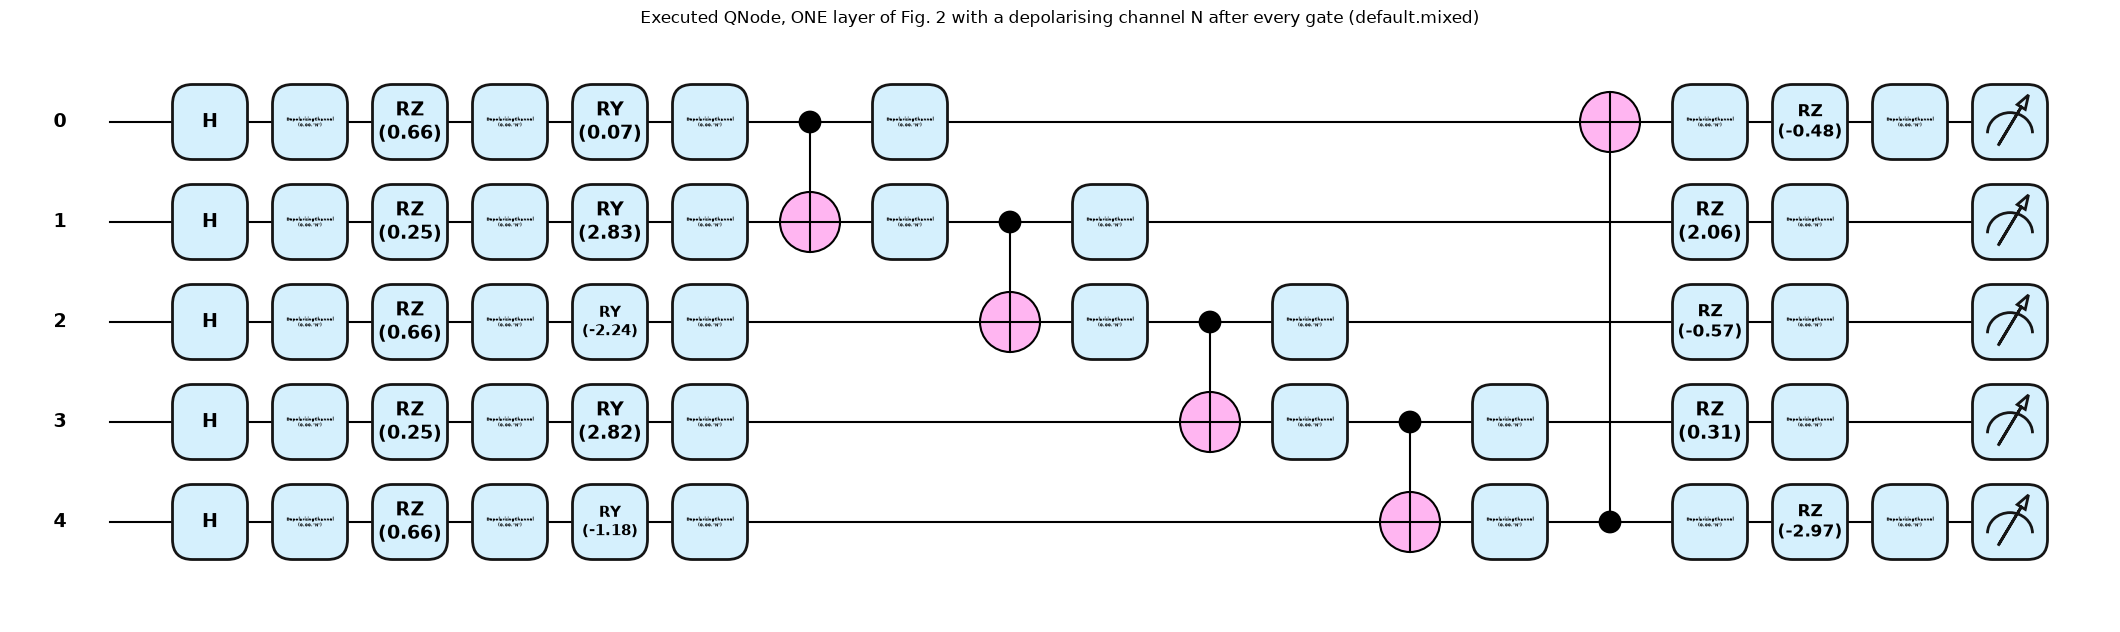

Matplotlib is building the font cache; this may take a moment.


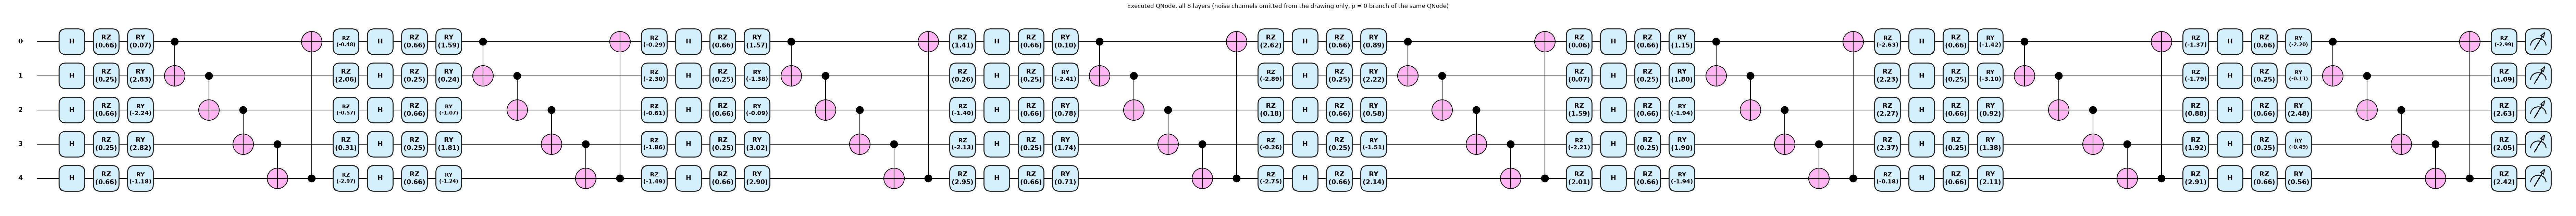

qubits: 5 | trainable parameters: 80 (RY + RZ per qubit per layer) | feature-map circuit gates per layer: 25 (5 H, 5 RZ(x), 5 RY, 5 CNOT, 5 RZ)
kernel circuit U(x2)^dagger U(x1) incl. noise: 880 operations, depth 288 (device level); 480 depolarising channels


In [7]:
import pennylane as qml
print("PennyLane", qml.__version__)
dev = qml.device("default.mixed", wires=N_QUBITS)          # the backend named in the paper (density-matrix simulator)

# CHOICE: the paper only gives Fig. 2. Per layer: H on every qubit (superposition layer), RZ(x_i) (embedding layer),
# RY(theta) on every qubit and a ring of CNOTs (trainable layer / "ring broadcast"), then RZ(theta') on every qubit.
# Every gate is followed by a depolarising channel on each qubit it acts on.
def circuit_ops(x, th, n_layers, p, adjoint=False):
    gates = []
    for l in range(n_layers):
        gates += [("H", None, (q,)) for q in range(N_QUBITS)]
        gates += [("RZ", x[feat_qubit(q)], (q,)) for q in range(N_QUBITS)]
        gates += [("RY", th[l, 0, q], (q,)) for q in range(N_QUBITS)]
        gates += [("CNOT", None, (c, t)) for c, t in RING]
        gates += [("RZ", th[l, 1, q], (q,)) for q in range(N_QUBITS)]
    for name, par, w in (gates[::-1] if adjoint else gates):     # adjoint circuit = reversed order, inverted angles
        if name == "H": qml.Hadamard(w[0])
        elif name == "CNOT": qml.CNOT(list(w))
        elif name == "RZ": qml.RZ(-par if adjoint else par, w[0])
        else: qml.RY(-par if adjoint else par, w[0])
        if p > 0:
            for q in w: qml.DepolarizingChannel(p, q, id="N")

@qml.qnode(dev)
def feature_map_qnode(x, th, n_layers, p):                         # U_E(theta, x) with noise: the encoding circuit of Fig. 2
    circuit_ops(x, th, n_layers, p)
    return qml.state()

@qml.qnode(dev, interface="torch", diff_method="backprop")
def kernel_qnode(x1, x2, th, n_layers, p):                         # the kernel circuit that is "executed": U(x2)^dagger U(x1), P0 projector
    circuit_ops(x1, th, n_layers, p); circuit_ops(x2, th, n_layers, p, adjoint=True)
    return qml.expval(qml.Projector(np.zeros(N_QUBITS, dtype=int), wires=range(N_QUBITS)))

rs = np.random.default_rng(1)
th_demo = rs.uniform(-np.pi, np.pi, (N_LAYERS, 2, N_QUBITS)); x_demo = rs.uniform(0, 1, 2)
fig, ax = qml.draw_mpl(feature_map_qnode, decimals=2, style="pennylane")(x_demo, th_demo, 1, P_NORMAL)
fig.suptitle("Executed QNode, ONE layer of Fig. 2 with a depolarising channel N after every gate (default.mixed)", y=1.02); plt.show()
fig, ax = qml.draw_mpl(feature_map_qnode, decimals=2, style="pennylane")(x_demo, th_demo, N_LAYERS, 0.0)
fig.suptitle("Executed QNode, all %d layers (noise channels omitted from the drawing only, p = 0 branch of the same QNode)" % N_LAYERS, y=1.02); plt.show()

th_t = torch.tensor(th_demo)
specs = qml.specs(kernel_qnode, level="device")(torch.tensor(x_demo), torch.tensor(x_demo[::-1].copy()), th_t, N_LAYERS, P_NORMAL)
n_noise = 2 * N_LAYERS * (5 + 5 + 5 + 10 + 5)
print("qubits:", N_QUBITS, "| trainable parameters:", th_demo.size, "(RY + RZ per qubit per layer)",
      "| feature-map circuit gates per layer: 25 (5 H, 5 RZ(x), 5 RY, 5 CNOT, 5 RZ)")
print("kernel circuit U(x2)^dagger U(x1) incl. noise: %d operations, depth %d (device level); %d depolarising channels" % (
      specs.resources.num_gates, specs.resources.depth, n_noise))

In [8]:
# Equivalence check: the fast Pauli-transfer-matrix simulator that trains the models == the real PennyLane QNode (density matrices)
rs = np.random.default_rng(7); worst = 0.0
for p in (0.0, P_NORMAL, 0.01, P_QUITE_HIGH):
    for rep in range(2):
        th = rs.uniform(-np.pi, np.pi, (N_LAYERS, 2, N_QUBITS)); x1, x2 = rs.uniform(0, 1, (2, 2))
        k_qnode = float(kernel_qnode(torch.tensor(x1), torch.tensor(x2), torch.tensor(th), N_LAYERS, p))
        k_sim = float(kernel_matrix(torch.tensor(x1[None]), torch.tensor(x2[None]), torch.tensor(th), N_LAYERS, p))
        worst = max(worst, abs(k_qnode - k_sim))
print("max |K_QNode - K_simulator| over 8 random pairs (p in 0, 0.05 %%, 1 %%, 5 %%): %.2e" % worst)
assert worst < 1e-5      # PennyLane's torch interface works in single precision for some gates, hence the 1e-5 tolerance
# ... and the same for the gradient that drives the training (alignment of a 4-sample batch w.r.t. all 80 angles)
xb = torch.tensor(rs.uniform(0, 1, (4, 2))); yb = torch.tensor([1., -1., 1., -1.]); thb = torch.tensor(rs.uniform(-np.pi, np.pi, (2, 2, N_QUBITS)))
def align_qnode(th):
    K = torch.stack([torch.stack([kernel_qnode(xb[i], xb[j], th, 2, 0.01) for j in range(4)]) for i in range(4)])
    return alignment(K, yb)
t1 = thb.clone().requires_grad_(True); align_qnode(t1).backward()
t2 = thb.clone().requires_grad_(True); alignment(kernel_matrix(xb, xb, t2, 2, 0.01), yb).backward()
print("gradient check (2 layers, p = 1 %%): max |dA_QNode - dA_simulator| = %.2e" % (t1.grad - t2.grad).abs().max().item())
assert (t1.grad - t2.grad).abs().max().item() < 1e-4
print("Equivalence asserted: all numbers below come from the simulator that equals the real QNode.")

max |K_QNode - K_simulator| over 8 random pairs (p in 0, 0.05 %, 1 %, 5 %): 1.28e-06


gradient check (2 layers, p = 1 %): max |dA_QNode - dA_simulator| = 6.98e-09
Equivalence asserted: all numbers below come from the simulator that equals the real QNode.


## 2. Data

Dataset 1 (Fig. 4) is a synthetic 4x4 checkerboard on the unit square: 16 cells, class = $(i+j) \bmod 2$, Gaussian blobs around the cell centres, split over four units by quadrant, so every unit sees only a *quarter* of the picture (heterogeneous data). Dataset 2 (Fig. 5) is real MNIST (digits 7 and 9) compressed by an autoencoder to two coordinates in the unit square and split at random over four units. The two coordinates are the two rotation angles that enter the circuit (as in the paper: $x_1$ on qubits 1, 3, 5 and $x_2$ on qubits 2, 4). The autoencoder is trained on images of the MNIST *train* split, the 240 experiment images come from the *test* split, so the encoder never saw them.

In [9]:
# ---------------- Dataset 1: checkerboard (Fig. 4) ----------------
def make_checkerboard(seed, per_cell=PER_CELL, sigma=SIGMA):
    r = np.random.default_rng(seed); X, y, cell = [], [], []
    for i in range(4):
        for j in range(4):
            c = np.array([0.125 + 0.25 * i, 0.125 + 0.25 * j])                    # centre of checkerboard cell (i, j)
            X.append(np.clip(c + sigma * r.standard_normal((per_cell, 2)), 0, 1))   # Gaussian blob inside the 1x1 square
            y += [(i + j) % 2] * per_cell; cell += [4 * i + j] * per_cell
    return np.vstack(X), np.array(y), np.array(cell)
def quadrant(X):                       # heterogeneous split of Fig. 4: node D1..D4 = the four 0.5 x 0.5 quadrants
    return (X[:, 0] >= 0.5).astype(int) * 2 + (X[:, 1] >= 0.5).astype(int)
X1, y1, cell1 = make_checkerboard(SEED)
X1tr, X1te, y1tr, y1te, cell1tr, cell1te = train_test_split(X1, y1, cell1, test_size=TEST_SIZE, stratify=cell1, random_state=SEED)
node1_tr, node1_te = quadrant(X1tr), quadrant(X1te)
print("Dataset 1: %d points -> %d train / %d test; local training sizes %s" % (len(X1), len(X1tr), len(X1te), np.bincount(node1_tr)))

# ---------------- Dataset 2: MNIST 7 vs 9 reduced to 2-D by an autoencoder (Fig. 5) ----------------
from huggingface_hub import hf_hub_download
def mnist_part(split):
    f = hf_hub_download("ylecun/mnist", "mnist/%s-00000-of-00001.parquet" % split, repo_type="dataset", local_dir=DATA_DIR, token=HF_TOKEN or None)
    df = pd.read_parquet(f); df = df[df.label.isin(DIGITS)].reset_index(drop=True)
    return df
from PIL import Image
def decode(df): return np.stack([np.array(Image.open(io.BytesIO(b["bytes"]))) for b in df.image]).reshape(len(df), -1) / 255.0
mn_train, mn_test = mnist_part("train"), mnist_part("test")
ae_df = mn_train.sample(AE_TRAIN_IMAGES, random_state=SEED); ae_pix = decode(ae_df)
exp_df = pd.concat([mn_test[mn_test.label == d].sample(N_PER_CLASS, random_state=SEED) for d in DIGITS]).reset_index(drop=True)
exp_pix = decode(exp_df); exp_lab = exp_df.label.values
print("MNIST 7/9 train-split images for the autoencoder:", ae_pix.shape, "| experiment images (test split):", exp_pix.shape)

import torch.nn as nn
torch.manual_seed(SEED)
def fc_stack(dims):
    layers = []
    for i, (a, b) in enumerate(zip(dims[:-1], dims[1:])):
        layers.append(nn.Linear(a, b))
        if i < len(dims) - 2: layers.append(nn.LeakyReLU(0.1))
    return nn.Sequential(*layers)
AE_DIMS = [784, 400, 100, 25, 2]                                   # CHOICE: 4 fully connected layers with gradually decreasing width (paper Fig. 5)
encoder, decoder = fc_stack(AE_DIMS), nn.Sequential(fc_stack(AE_DIMS[::-1]), nn.Sigmoid())
opt = torch.optim.Adam(list(encoder.parameters()) + list(decoder.parameters()), 1e-3)
T = torch.tensor(ae_pix, dtype=torch.float32); losses = []
for ep in range(AE_EPOCHS):
    perm = torch.randperm(len(T))
    for i in range(0, len(T), 128):
        b = T[perm[i:i + 128]]; loss = ((decoder(encoder(b)) - b) ** 2).mean(); opt.zero_grad(); loss.backward(); opt.step()
    losses.append(loss.item())
print("autoencoder reconstruction MSE: first epoch %.4f -> last epoch %.4f" % (losses[0], losses[-1]))
with torch.no_grad():
    Z_ae = encoder(T).numpy(); lo, hi = Z_ae.min(0), Z_ae.max(0)         # min-max scaling to the 1 x 1 square is fitted on the AE training images
    Z2 = np.clip((encoder(torch.tensor(exp_pix, dtype=torch.float32)).numpy() - lo) / (hi - lo), 0, 1)
X2, y2 = Z2.astype(np.float64), (exp_lab == DIGITS[1]).astype(int)       # label 1 = digit 9, label 0 = digit 7
X2tr, X2te, y2tr, y2te, pix2tr, pix2te = train_test_split(X2, y2, exp_pix, test_size=TEST_SIZE, stratify=y2, random_state=SEED)
rs2 = np.random.default_rng(SEED)
node2_tr = rs2.permutation(np.arange(len(X2tr)) % N_NODES)             # Dataset 2: RANDOM partition into 4 equal local sets (Fig. 5)
node2_te = rs2.permutation(np.arange(len(X2te)) % N_NODES)
print("Dataset 2: %d points -> %d train / %d test; local training sizes %s" % (len(X2), len(X2tr), len(X2te), np.bincount(node2_tr)))

Dataset 1: 240 points -> 180 train / 60 test; local training sizes [47 43 44 46]


MNIST 7/9 train-split images for the autoencoder: (6000, 784) | experiment images (test split): (240, 784)


autoencoder reconstruction MSE: first epoch 0.0570 -> last epoch 0.0262


Dataset 2: 240 points -> 180 train / 60 test; local training sizes [45 45 45 45]


## Dataset Exploration and Visualisation

Both datasets are real observations: Dataset 1 is generated exactly as the paper describes (Gaussian blobs on a checkerboard; the generator is the data source, there is nothing to download), Dataset 2 is real MNIST handwriting (digits 7 and 9) passed through the autoencoder. Below: shapes, feature names, original labels and class counts, class distributions, and 2-D scatter plots in which every point is a real observation coloured by its ground-truth label.

Dataset 1 shape: (240, 5) | features: ['x1', 'x2'] | original labels: [np.int64(0), np.int64(1)] (cell colour of the checkerboard: (i + j) mod 2)
class counts: {0: 120, 1: 120} | points per cell: [15] | per node (train): [47, 43, 44, 46]
      x1     x2  label  checkerboard_cell  node(quadrant)
0  0.140  0.073      0                  0               1
1  0.163  0.172      0                  0               1
2  0.027  0.060      0                  0               1
3  0.131  0.109      0                  0               1


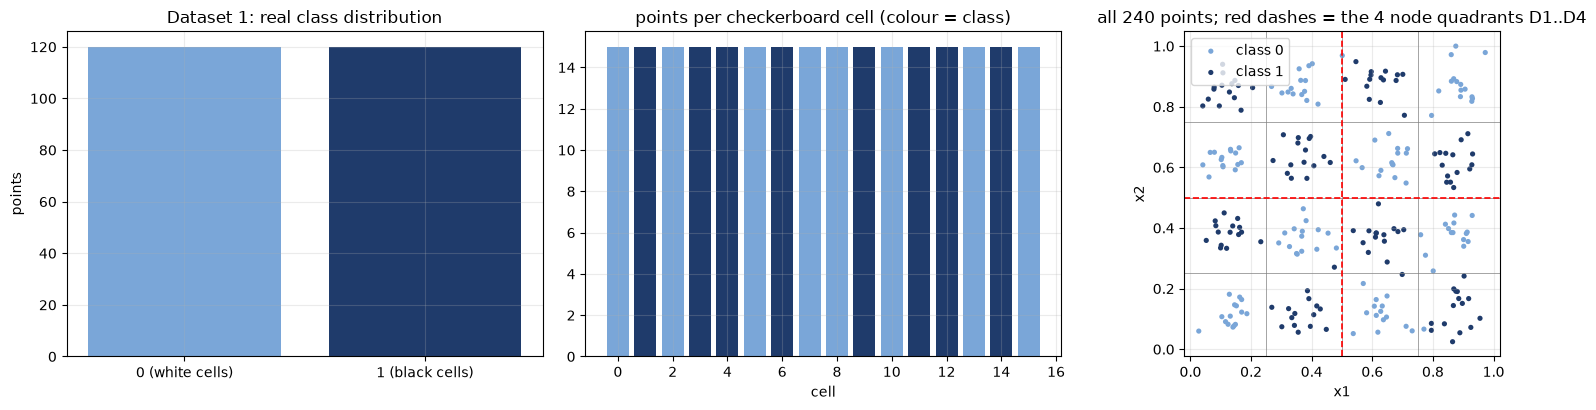

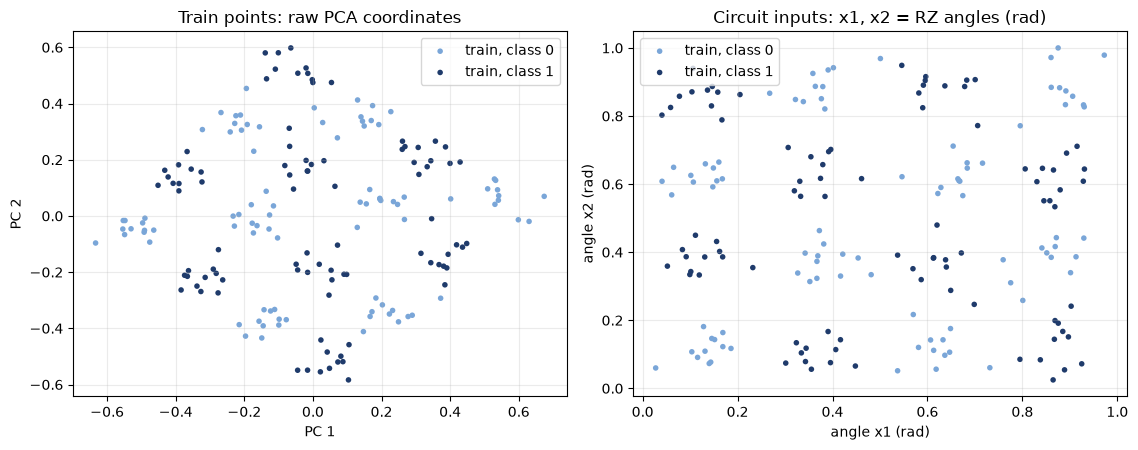

In [10]:
# ---- Dataset 1: checkerboard ----
df1 = pd.DataFrame(X1, columns=["x1", "x2"]); df1["label"] = y1; df1["checkerboard_cell"] = cell1; df1["node(quadrant)"] = quadrant(X1) + 1
print("Dataset 1 shape:", df1.shape, "| features:", ["x1", "x2"], "| original labels:", sorted(df1.label.unique()), "(cell colour of the checkerboard: (i + j) mod 2)")
print("class counts:", df1.label.value_counts().sort_index().to_dict(), "| points per cell:", df1.checkerboard_cell.value_counts().unique().tolist(), "| per node (train):", np.bincount(node1_tr).tolist())
print(df1.head(4).round(3).to_string())
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].bar(["0 (white cells)", "1 (black cells)"], np.bincount(y1), color=["#7aa6d8", "#1f3b6b"]); ax[0].set_title("Dataset 1: real class distribution"); ax[0].set_ylabel("points")
ax[1].bar(range(16), np.bincount(cell1), color=["#7aa6d8" if (c // 4 + c % 4) % 2 == 0 else "#1f3b6b" for c in range(16)]); ax[1].set_title("points per checkerboard cell (colour = class)"); ax[1].set_xlabel("cell")
for c, col in ((0, "#7aa6d8"), (1, "#1f3b6b")):
    ax[2].scatter(X1[y1 == c, 0], X1[y1 == c, 1], s=14, c=col, label="class %d" % c, edgecolor="none")
for k in (0.25, 0.5, 0.75): ax[2].axvline(k, c="gray", lw=0.5); ax[2].axhline(k, c="gray", lw=0.5)
ax[2].axvline(0.5, c="red", lw=1.2, ls="--"); ax[2].axhline(0.5, c="red", lw=1.2, ls="--")
ax[2].set_title("all 240 points; red dashes = the 4 node quadrants D1..D4"); ax[2].set_xlabel("x1"); ax[2].set_ylabel("x2"); ax[2].legend(); ax[2].set_aspect("equal")
plt.tight_layout(); plt.show()

# raw PCA coordinates (fitted on the training split) and the angles that enter the circuit
pca1 = PCA(n_components=2, random_state=SEED).fit(X1tr); P1tr, P1te = pca1.transform(X1tr), pca1.transform(X1te)
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.6))
for c, col in ((0, "#7aa6d8"), (1, "#1f3b6b")):
    ax[0].scatter(P1tr[y1tr == c, 0], P1tr[y1tr == c, 1], s=16, c=col, label="train, class %d" % c, edgecolor="none")
    ax[1].scatter(X1tr[y1tr == c, 0], X1tr[y1tr == c, 1], s=16, c=col, label="train, class %d" % c, edgecolor="none")
ax[0].set_title("Train points: raw PCA coordinates"); ax[0].set_xlabel("PC 1"); ax[0].set_ylabel("PC 2"); ax[0].legend()
ax[1].set_title("Circuit inputs: x1, x2 = RZ angles (rad)"); ax[1].set_xlabel("angle x1 (rad)"); ax[1].set_ylabel("angle x2 (rad)"); ax[1].legend()
plt.tight_layout(); plt.show()

Dataset 2 shape: raw images (240, 784) -> latent (240, 2) | features: 784 pixel intensities in [0, 1] -> 2 latent coordinates (z1, z2) scaled to [0, 1]
original labels: [7, 9] | class counts: {7: 120, 9: 120} | train/test: 180 60 | per node (train): [45, 45, 45, 45]


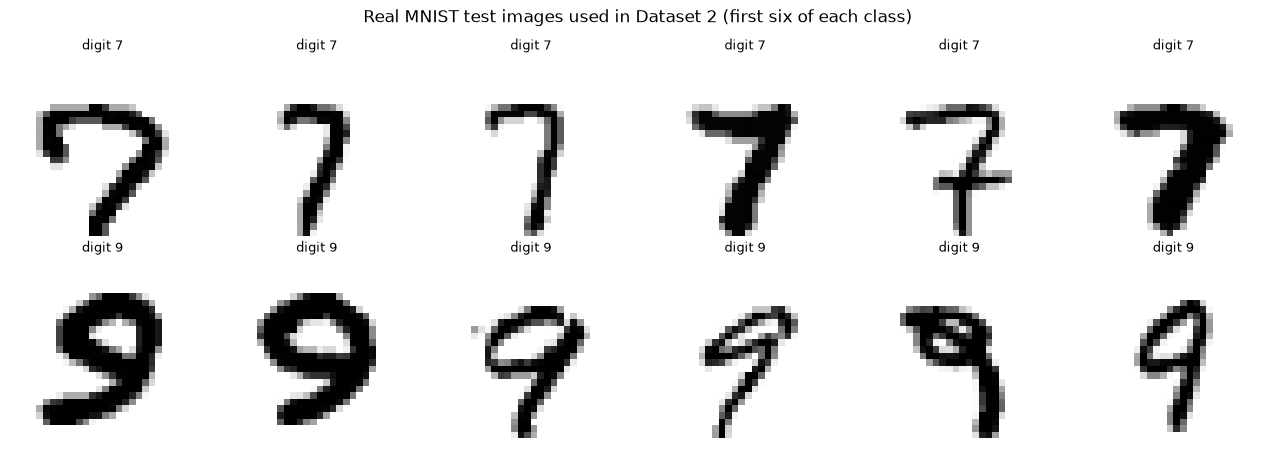

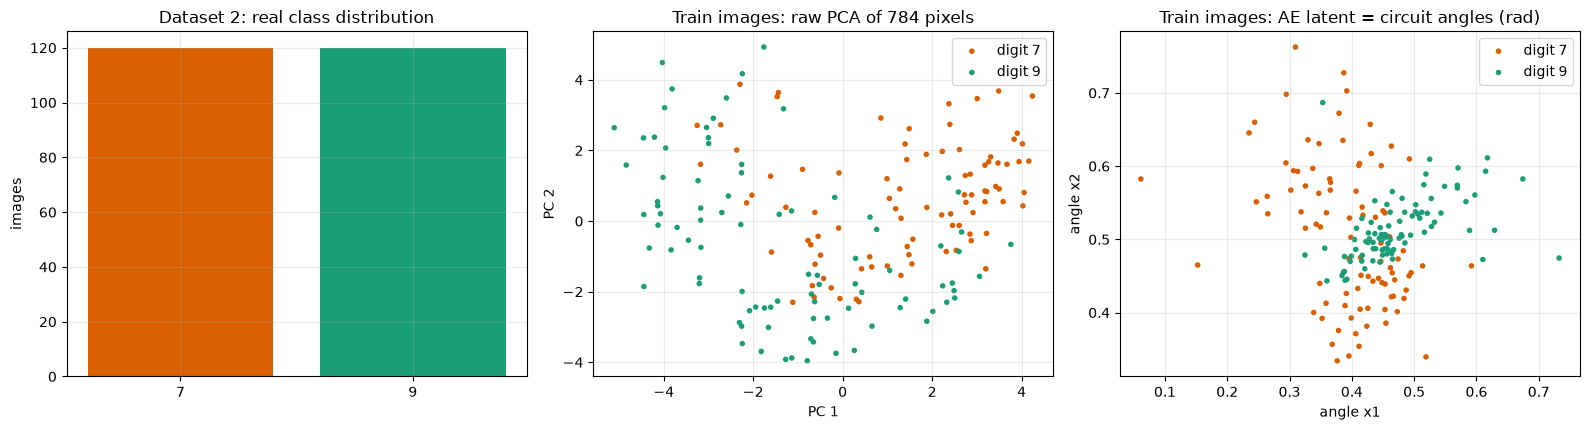

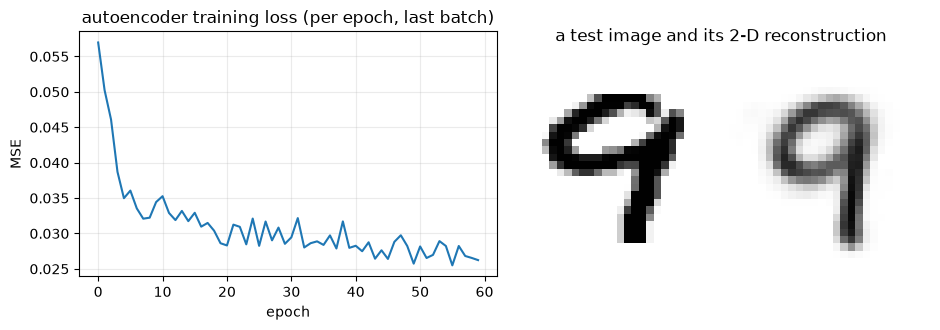

In [11]:
# ---- Dataset 2: MNIST 7 vs 9 -> 2-D autoencoder latent ----
print("Dataset 2 shape: raw images", exp_pix.shape, "-> latent", X2.shape, "| features: 784 pixel intensities in [0, 1] -> 2 latent coordinates (z1, z2) scaled to [0, 1]")
print("original labels:", sorted(set(exp_lab.tolist())), "| class counts:", pd.Series(exp_lab).value_counts().sort_index().to_dict(),
      "| train/test:", len(X2tr), len(X2te), "| per node (train):", np.bincount(node2_tr).tolist())
fig, ax = plt.subplots(2, 6, figsize=(13, 4.6))
for r_, d in enumerate(DIGITS):
    idxs = np.where(exp_lab == d)[0][:6]
    for c_, i in enumerate(idxs): ax[r_, c_].imshow(exp_pix[i].reshape(28, 28), cmap="gray_r"); ax[r_, c_].axis("off"); ax[r_, c_].set_title("digit %d" % d, fontsize=9)
plt.suptitle("Real MNIST test images used in Dataset 2 (first six of each class)"); plt.tight_layout(); plt.show()
pca2 = PCA(n_components=2, random_state=SEED).fit(pix2tr); P2tr = pca2.transform(pix2tr)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
ax[0].bar([str(d) for d in DIGITS], [int((exp_lab == d).sum()) for d in DIGITS], color=["#d95f02", "#1b9e77"]); ax[0].set_title("Dataset 2: real class distribution"); ax[0].set_ylabel("images")
cols = {0: "#d95f02", 1: "#1b9e77"}
for c in (0, 1):
    ax[1].scatter(P2tr[y2tr == c, 0], P2tr[y2tr == c, 1], s=16, c=cols[c], label="digit %d" % DIGITS[c], edgecolor="none")
    ax[2].scatter(X2tr[y2tr == c, 0], X2tr[y2tr == c, 1], s=16, c=cols[c], label="digit %d" % DIGITS[c], edgecolor="none")
ax[1].set_title("Train images: raw PCA of 784 pixels"); ax[1].set_xlabel("PC 1"); ax[1].set_ylabel("PC 2"); ax[1].legend()
ax[2].set_title("Train images: AE latent = circuit angles (rad)"); ax[2].set_xlabel("angle x1"); ax[2].set_ylabel("angle x2"); ax[2].legend()
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.4))
ax[0].plot(losses); ax[0].set_title("autoencoder training loss (per epoch, last batch)"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("MSE")
with torch.no_grad(): rec = decoder(encoder(torch.tensor(pix2te[:1], dtype=torch.float32))).numpy().reshape(28, 28)
ax[1].imshow(np.hstack([pix2te[0].reshape(28, 28), rec]), cmap="gray_r"); ax[1].axis("off"); ax[1].set_title("a test image and its 2-D reconstruction"); plt.tight_layout(); plt.show()

## 3. The decentralised network

Four quantum computing units (QU1..QU4) are connected by a **ring** (Dataset 1) or a **fully connected** graph (Dataset 2); QU2 (index 1) is the unit that has high noise or turns malicious. The aggregation weights are the Metropolis weights of the graph, which are symmetric and doubly stochastic as required by Eq. (26). The second-largest eigenvalue modulus controls how fast consensus is reached (Eq. 32): the fully connected graph averages in one step, the ring needs several.

ring W (Dataset 1):
 [[0.333 0.333 0.    0.333]
 [0.333 0.333 0.333 0.   ]
 [0.    0.333 0.333 0.333]
 [0.333 0.    0.333 0.333]] 
second largest |eigenvalue| (consensus rate, Eq. 32): ring 0.333, fully connected 0.000


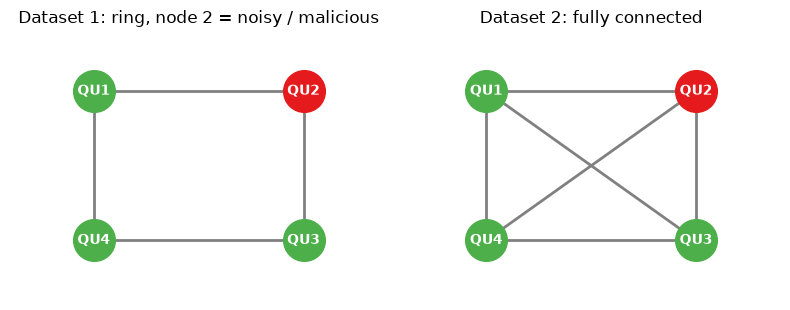

In [12]:
def draw_network(ax, adj, title, attacker=None):
    pos = {0: (0, 1), 1: (1, 1), 2: (1, 0), 3: (0, 0)}                       # node i+1 on a square: ring neighbours are drawn as edges
    for i in range(len(adj)):
        for j in range(i + 1, len(adj)):
            if adj[i, j]: ax.plot([pos[i][0], pos[j][0]], [pos[i][1], pos[j][1]], c="gray", lw=2, zorder=1)
    for i, (px, py) in pos.items():
        ax.scatter([px], [py], s=900, c="#e41a1c" if i == attacker else "#4daf4a", zorder=2); ax.text(px, py, "QU%d" % (i + 1), ha="center", va="center", color="w", fontweight="bold")
    ax.set_xlim(-0.4, 1.4); ax.set_ylim(-0.4, 1.4); ax.axis("off"); ax.set_title(title)
ADJ_RING, ADJ_FULL = ring_adj(N_NODES), full_adj(N_NODES)
W_RING, W_FULL = metropolis(ADJ_RING), metropolis(ADJ_FULL)
for Wm in (W_RING, W_FULL): assert np.allclose(Wm.sum(0), 1) and np.allclose(Wm.sum(1), 1) and np.allclose(Wm, Wm.T)       # doubly stochastic
print("ring W (Dataset 1):\n", W_RING.round(3), "\nsecond largest |eigenvalue| (consensus rate, Eq. 32): ring %.3f, fully connected %.3f" % (
      sorted(np.abs(np.linalg.eigvalsh(W_RING)))[-2], sorted(np.abs(np.linalg.eigvalsh(W_FULL)))[-2]))
fig, ax = plt.subplots(1, 2, figsize=(8, 3.2)); draw_network(ax[0], ADJ_RING, "Dataset 1: ring, node 2 = noisy / malicious", ATTACKER); draw_network(ax[1], ADJ_FULL, "Dataset 2: fully connected", ATTACKER); plt.tight_layout(); plt.show()

## 4. Classical baselines on identical inputs

Both datasets are two-dimensional, so a classical kernel machine is a strong reference. The table gives an RBF-SVM (hyper-parameters tuned by cross-validation on the training data only) and a random forest, trained and scored exactly like Score1/2/3: on each unit's local data and on all training data, same test sets. This shows how much of the paper's numbers is merely the difficulty of the data and how much the quantum kernel adds. The paper does not report classical baselines.

In [13]:
# Classical baselines on EXACTLY the same 2-D inputs, with the same train/test split and the same node partitions.
# Score1: train on the local training set, test on the local test set; Score2: same model, whole test set; Score3: train on all training data, test on the whole test set.
def tuned_svc(X, y):
    gs = GridSearchCV(SVC(kernel="rbf"), {"C": [1, 10, 100, 1000], "gamma": [1, 10, 100, 300]}, cv=3).fit(X, y)       # hyper-parameters on the training data only
    return gs.best_estimator_
def classical_table(Xtr, ytr, Xte, yte, ntr, nte, name):
    rows = []
    for mname, make in (("SVC (rbf, tuned on train)", lambda X, y: tuned_svc(X, y)), ("Random forest", lambda X, y: RandomForestClassifier(200, random_state=SEED).fit(X, y))):
        s3 = make(Xtr, ytr).score(Xte, yte); s1, s2 = [], []
        for i in range(N_NODES):
            m = make(Xtr[ntr == i], ytr[ntr == i])
            s2.append(m.score(Xte, yte)); s1.append(m.score(Xte[nte == i], yte[nte == i]) if (nte == i).any() else np.nan)
        rows.append({"dataset": name, "classical model": mname, "Score1 (local/local)": np.nanmean(s1), "Score2 (local/whole)": np.mean(s2), "Score3 (whole/whole)": s3})
    return pd.DataFrame(rows)
baseline = pd.concat([classical_table(X1tr, y1tr, X1te, y1te, node1_tr, node1_te, "Dataset 1 (checkerboard)"),
                      classical_table(X2tr, y2tr, X2te, y2te, node2_tr, node2_te, "Dataset 2 (MNIST 7/9)")], ignore_index=True)
display(baseline.round(3))

,dataset,classical model,Score1 (local/local),Score2 (local/whole),Score3 (whole/whole)
0,Dataset 1 (checkerboard),"SVC (rbf, tuned on train)",0.965,0.617,0.967
1,Dataset 1 (checkerboard),Random forest,0.948,0.612,0.883
2,Dataset 2 (MNIST 7/9),"SVC (rbf, tuned on train)",0.933,0.925,0.967
3,Dataset 2 (MNIST 7/9),Random forest,0.900,0.871,0.933


## 5. Algorithm 1 and RDQKL

The training code (inside `rdqkl_core.py`, cell above) follows the paper line by line:

1. each unit draws $q$ local samples, computes the kernel of this mini-batch with its **own** noise level, the alignment (Eq. 18) and its gradient, and takes a gradient-descent step (Eqs. 23-24);
2. the units exchange the half-step parameters; a malicious unit instead sends a Gaussian vector (Eq. 33) or the negative mean of what it received (Eq. 34);
3. each honest unit aggregates, either with the weighted mean (Eq. 26, plain decentralised QKL), with the **clip** rule (Eq. 36, RDQKL) or, as an extra baseline the paper does not report, with a coordinate-wise **median**.

The centralised reference is one unit holding all training data with the same step size and mini-batch size; the local reference is every unit training alone ($W=I$). Experiments run in parallel worker processes (`N_WORKERS`).

In [14]:
from concurrent.futures import ProcessPoolExecutor, as_completed
import multiprocessing as mp
def run_jobs(specs, workers=N_WORKERS):
    """Run experiments in parallel worker processes (spawn context: works on Linux, macOS and Windows); results keyed by spec name."""
    out, t0 = {}, time.time()
    if workers <= 1:
        for s in specs: out[s["name"]] = rdqkl_core.run_job(s); print("  done %-32s %5.0f s" % (s["name"], out[s["name"]]["seconds"]))
        return out
    with ProcessPoolExecutor(workers, mp_context=mp.get_context("spawn")) as ex:
        futs = {ex.submit(rdqkl_core.run_job, s): s["name"] for s in specs}
        for f in as_completed(futs):
            out[futs[f]] = f.result(); print("  done %-32s %5.0f s  (elapsed %4.0f s)" % (futs[f], out[futs[f]]["seconds"], time.time() - t0))
    return out

ev_rs = np.random.default_rng(1)
def make_data(Xtr, ytr, Xte, yte, node_te):
    ev = ev_rs.choice(len(Xtr), EVAL_POINTS, replace=False)
    return dict(Xtr=Xtr, ytr=ytr, Xte=Xte, yte=yte, node_te=node_te, eval_X=Xtr[ev], eval_y=ytr[ev])
DATA1 = make_data(X1tr, y1tr, X1te, y1te, node1_te); DATA2 = make_data(X2tr, y2tr, X2te, y2te, node2_te)
def local_sets(Xtr, ytr, ntr): return [Xtr[ntr == i] for i in range(N_NODES)], [ytr[ntr == i] for i in range(N_NODES)]
LOC1 = local_sets(X1tr, y1tr, node1_tr); LOC2 = local_sets(X2tr, y2tr, node2_tr)

def spec(name, mode, data, loc, W, p_nodes, iters, seed, attack=None, tau=None, aggregator="mean"):
    base = dict(name=name, mode=mode, data=data, L=N_LAYERS, W=W, p_nodes=list(p_nodes), iters=iters, lr=LR, q=Q_BATCH, seed=seed,
                attack=attack, attacker=ATTACKER if attack else None, tau=tau, aggregator=aggregator, eval_every=max(iters // 10, 1))
    if mode == "central": base.update(nodes_X=[data["Xtr"]], nodes_y=[data["ytr"]], W=np.ones((1, 1)), p_nodes=[p_nodes[0]])
    elif mode == "local":  base.update(nodes_X=loc[0], nodes_y=loc[1], W=np.eye(N_NODES))
    else:                  base.update(nodes_X=loc[0], nodes_y=loc[1])
    return base
print("experiment helpers ready")

experiment helpers ready


## 6. How noise acts on the kernel and on learning (Section III-C and IV-B)

Two quick measurements before the big experiments. (a) The paper models noise as a *global* depolarising channel, $K_e=(1-p)K+p/D$. Our noise is a depolarising channel after every gate, so we fit $K_{noisy}\approx a\,K+b$ over a random kernel matrix and compare the offset with the value $(1-a)/D$ that the global model predicts. (b) Eq. (21) says the alignment gradient shrinks when noise is strong: we measure its norm at fixed parameters and batch. Then a Fig. 3 analogue: one unit trains on all of Dataset 1 under several noise levels.

,per-gate p,equivalent global p = 1-(1-p)^480,fit slope (1-p_eff),fit offset,"offset predicted by Eq. 14, (1-slope)/32",R^2 of linear fit
0,0.0005,0.2134,0.7913,0.0072,0.0065,1.0000
1,0.0020,0.6175,0.3926,0.0205,0.0190,0.9999
2,0.0050,0.9098,0.0973,0.0292,0.0282,0.9996
3,0.0100,0.9920,0.0097,0.0312,0.0309,0.9979
4,0.0500,1.0000,0.0000,0.0313,0.0312,0.8724


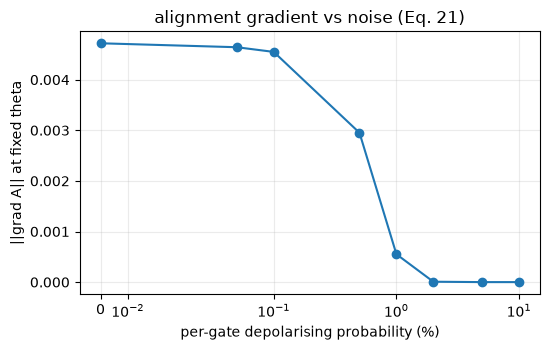

In [15]:
# (a) Effect of depolarising noise on the KERNEL itself (Section III-C): the paper models it as K_noisy = (1-p) K + p / D (Eqs. 12-14).
rs = np.random.default_rng(3); th_r = torch.tensor(rs.uniform(-np.pi, np.pi, (N_LAYERS, 2, N_QUBITS))); Xk = torch.tensor(rs.uniform(0, 1, (24, 2)))
K0 = kernel_matrix(Xk, Xk, th_r, N_LAYERS, 0.0).numpy().ravel()
rows = []
for p in (0.0005, 0.002, 0.005, 0.01, 0.05):
    Kp = kernel_matrix(Xk, Xk, th_r, N_LAYERS, p).numpy().ravel()
    a, b = np.polyfit(K0, Kp, 1); r2 = np.corrcoef(K0, Kp)[0, 1] ** 2
    rows.append({"per-gate p": p, "equivalent global p = 1-(1-p)^480": 1 - (1 - p) ** n_noise, "fit slope (1-p_eff)": a, "fit offset": b,
                 "offset predicted by Eq. 14, (1-slope)/32": (1 - a) / 2 ** N_QUBITS, "R^2 of linear fit": r2})
display(pd.DataFrame(rows).round(4))
# (b) Effect of noise on the learning signal: norm of the alignment gradient at the SAME parameters and the SAME batch (Eq. 21 predicts it shrinks for strong noise)
xb = torch.tensor(X1tr[:48]); yb = torch.tensor(2.0 * y1tr[:48] - 1); gn = []
for p in [0.0, 0.0005, 0.001, 0.005, 0.01, 0.02, 0.05, 0.1]:
    th = th_r.clone().requires_grad_(True); alignment(kernel_matrix(xb, xb, th, N_LAYERS, p), yb).backward(); gn.append((p, th.grad.norm().item()))
fig, ax = plt.subplots(1, 1, figsize=(5.6, 3.6)); ax.plot([g[0] * 100 for g in gn], [g[1] for g in gn], "o-"); ax.set_xscale("symlog", linthresh=0.05)
ax.set_xlabel("per-gate depolarising probability (%)"); ax.set_ylabel("||grad A|| at fixed theta"); ax.set_title("alignment gradient vs noise (Eq. 21)"); plt.tight_layout(); plt.show()

  done sweep p=0                           70 s  (elapsed  112 s)


  done sweep p=0.002                       69 s  (elapsed  116 s)


  done sweep p=0.001                       69 s  (elapsed  117 s)


  done sweep p=0.0005                      69 s  (elapsed  118 s)


  done sweep p=0.005                       57 s  (elapsed  169 s)


  done sweep p=0.01                        56 s  (elapsed  172 s)


  done sweep p=0.05                        56 s  (elapsed  173 s)


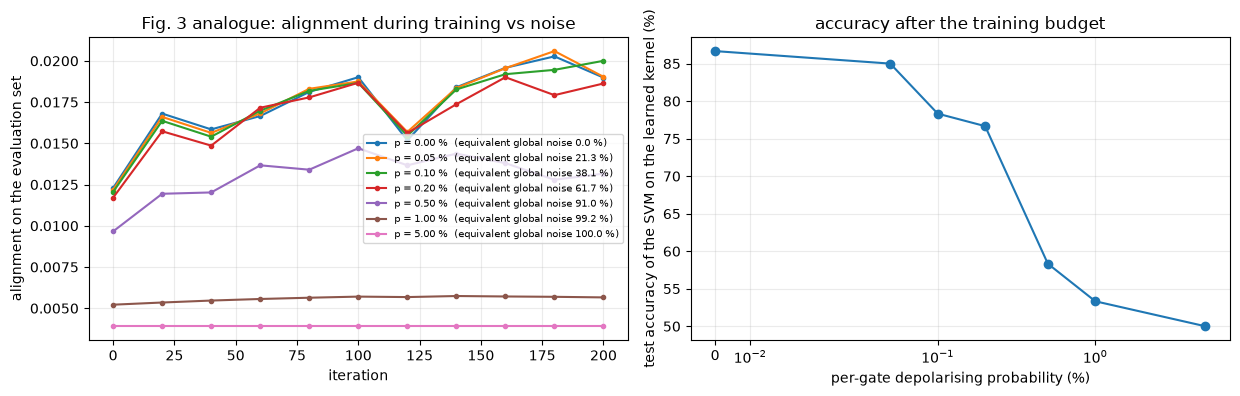

In [16]:
# Fig. 3 analogue: kernel-target alignment during training for several noise levels (one unit, all training data of Dataset 1)
sweep_specs = [spec("sweep p=%g" % p, "central", DATA1, LOC1, None, [p], SWEEP_ITERS, SEED) for p in SWEEP_P]
sweep = run_jobs(sweep_specs)
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4))
for p in SWEEP_P:
    h = sweep["sweep p=%g" % p]["hist"]; ks = [k for k, _ in h]; al = [a[0] for _, a in h]
    ax[0].plot(ks, al, marker=".", label="p = %.2f %%  (equivalent global noise %.1f %%)" % (100 * p, 100 * (1 - (1 - p) ** n_noise)))
ax[0].set_xlabel("iteration"); ax[0].set_ylabel("alignment on the evaluation set"); ax[0].set_title("Fig. 3 analogue: alignment during training vs noise"); ax[0].legend(fontsize=7)
ax[1].plot([100 * p for p in SWEEP_P], [100 * sweep["sweep p=%g" % p]["scores"][0, 2] for p in SWEEP_P], "o-"); ax[1].set_xscale("symlog", linthresh=0.05)
ax[1].set_xlabel("per-gate depolarising probability (%)"); ax[1].set_ylabel("test accuracy of the SVM on the learned kernel (%)"); ax[1].set_title("accuracy after the training budget")
plt.tight_layout(); plt.show()

## 7. Experiments on Dataset 1 (Table I): ring, heterogeneous split

All scenarios of Table I plus three extras: a coordinate-wise median aggregator against both attacks (a classical robust-aggregation baseline) and the clip without an attack (the price of the defence). Unit 2 is the high-noise / malicious one; in the "normal noise" rows every unit has $\tilde p=0.05\,\%$.

In [17]:
# ---------------- Dataset 1 (Table I): ring topology, heterogeneous split, node 2 = index 1 ----------------
PN  = lambda p2=None: [P_NORMAL, p2 if p2 is not None else P_NORMAL, P_NORMAL, P_NORMAL]
cen_it = DS1_ITERS * CEN_FACTOR
DS1_SCEN = [   # label, mode, W, p per node, iterations, attack, tau, aggregator
    ("dec normal",      "dec",     W_RING, PN(),                DS1_ITERS, None, None, "mean"),
    ("cen normal",      "central", None,   [P_NORMAL],          cen_it,    None, None, "mean"),
    ("loc normal",      "local",   None,   PN(),                DS1_ITERS, None, None, "mean"),
    ("dec rel-high",    "dec",     W_RING, PN(P_REL_HIGH_DS1),  DS1_ITERS, None, None, "mean"),
    ("cen rel-high",    "central", None,   [P_REL_HIGH_DS1],    cen_it,    None, None, "mean"),
    ("loc rel-high",    "local",   None,   PN(P_REL_HIGH_DS1),  DS1_ITERS, None, None, "mean"),
    ("dec quite-high",  "dec",     W_RING, PN(P_QUITE_HIGH),    DS1_ITERS, None, None, "mean"),
    ("gauss no-defence", "dec",    W_RING, PN(),                DS1_ITERS, "gaussian", None, "mean"),
    ("gauss RDQKL",     "dec",     W_RING, PN(),                DS1_ITERS, "gaussian", TAU_GAUSS, "clip"),
    ("sign no-defence", "dec",     W_RING, PN(),                DS1_ITERS, "signflip", None, "mean"),
    ("sign RDQKL",      "dec",     W_RING, PN(),                DS1_ITERS, "signflip", TAU_SIGN, "clip"),
    # extras that the paper does not report: a classical robust aggregator and the price of the clip without an attack
    ("gauss median",    "dec",     W_RING, PN(),                DS1_ITERS, "gaussian", None, "median"),
    ("sign median",     "dec",     W_RING, PN(),                DS1_ITERS, "signflip", None, "median"),
    ("clip %.2f, no attack" % TAU_GAUSS, "dec", W_RING, PN(),   DS1_ITERS, None, TAU_GAUSS, "clip"),
    ("clip %.2f, no attack" % TAU_SIGN,  "dec", W_RING, PN(),   DS1_ITERS, None, TAU_SIGN, "clip"),
]
specs1 = [spec("%s|%d" % (lab, s), mode, DATA1, LOC1, W, pn, it, s, atk, tau, agg) for s in SEEDS for (lab, mode, W, pn, it, atk, tau, agg) in DS1_SCEN]
t0 = time.time(); R1 = run_jobs(specs1); print("Dataset 1: %d runs in %.1f min" % (len(specs1), (time.time() - t0) / 60))

  done dec normal|42                      259 s  (elapsed  292 s)


  done loc normal|42                      263 s  (elapsed  304 s)


  done dec rel-high|42                    262 s  (elapsed  305 s)


  done cen normal|42                      303 s  (elapsed  346 s)


  done loc rel-high|42                    243 s  (elapsed  547 s)
  done dec quite-high|42                  242 s  (elapsed  547 s)


...

  done gauss median|42                    265 s  (elapsed  847 s)


  done sign median|42                     251 s  (elapsed 1057 s)


  done clip 0.50, no attack|42            255 s  (elapsed 1062 s)


  done clip 0.05, no attack|42            243 s  (elapsed 1084 s)


Dataset 1: 15 runs in 18.3 min


## 8. Experiments on Dataset 2 (Table II): fully connected, random split

In [18]:
# ---------------- Dataset 2 (Table II): fully connected topology, random split ----------------
cen_it2 = DS2_ITERS * CEN_FACTOR
DS2_SCEN = [
    ("dec normal",      "dec",     W_FULL, PN(),                DS2_ITERS, None, None, "mean"),
    ("cen normal",      "central", None,   [P_NORMAL],          cen_it2,   None, None, "mean"),
    ("dec rel-high",    "dec",     W_FULL, PN(P_REL_HIGH_DS2),  DS2_ITERS, None, None, "mean"),
    ("cen rel-high",    "central", None,   [P_REL_HIGH_DS2],    cen_it2,   None, None, "mean"),
    ("dec quite-high",  "dec",     W_FULL, PN(P_QUITE_HIGH),    DS2_ITERS, None, None, "mean"),
    ("gauss no-defence", "dec",    W_FULL, PN(),                DS2_ITERS, "gaussian", None, "mean"),
    ("gauss RDQKL",     "dec",     W_FULL, PN(),                DS2_ITERS, "gaussian", TAU_GAUSS, "clip"),
    ("sign no-defence", "dec",     W_FULL, PN(),                DS2_ITERS, "signflip", None, "mean"),
    ("sign RDQKL",      "dec",     W_FULL, PN(),                DS2_ITERS, "signflip", TAU_SIGN, "clip"),
]
specs2 = [spec("%s|%d" % (lab, s), mode, DATA2, LOC2, W, pn, it, s, atk, tau, agg) for s in SEEDS for (lab, mode, W, pn, it, atk, tau, agg) in DS2_SCEN]
t0 = time.time(); R2 = run_jobs(specs2); print("Dataset 2: %d runs in %.1f min" % (len(specs2), (time.time() - t0) / 60))

  done dec normal|42                      203 s  (elapsed  257 s)


  done dec rel-high|42                    203 s  (elapsed  258 s)


  done cen normal|42                      230 s  (elapsed  285 s)


  done cen rel-high|42                    229 s  (elapsed  285 s)


  done gauss no-defence|42                149 s  (elapsed  407 s)


  done dec quite-high|42                  151 s  (elapsed  408 s)


  done gauss RDQKL|42                     142 s  (elapsed  427 s)
  done sign no-defence|42                 142 s  (elapsed  427 s)


  done sign RDQKL|42                       97 s  (elapsed  504 s)


Dataset 2: 9 runs in 8.6 min


### Table I analogue

Columns follow the paper: iteration times, Score1 (local/local), Score2 (local train, whole test), Score3 (whole/whole). "nb" is this notebook, "paper" the published value. Averages are over the honest units as in the paper's footnotes; the paper's centralised rows have a single accuracy which we compare with Score3.

Dataset 1: alignment on the evaluation set 0.0122 -> 0.0465 (normal decentralised run); target for 'iteration times' = 0.0293
Dataset 2: alignment on the evaluation set 0.0170 -> 0.0444 (normal decentralised run); target for 'iteration times' = 0.0307


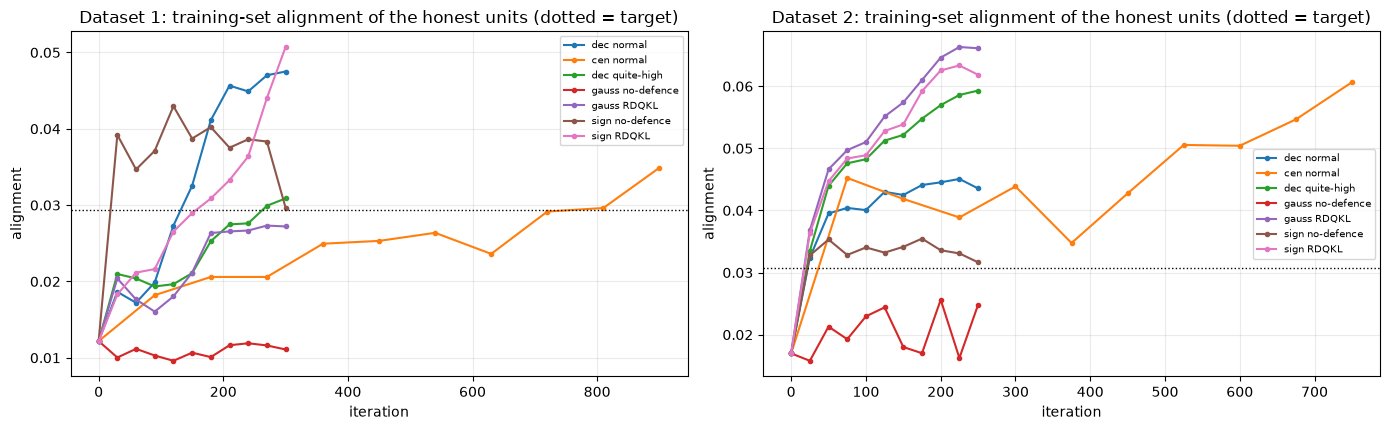

In [19]:
# ---------------- turning raw runs into the paper's metrics ----------------
def res(R, label): return [R["%s|%d" % (label, s)] for s in SEEDS]
def curve(r):                                           # (checkpoints, units)
    return np.array([k for k, _ in r["hist"]]), np.stack([a for _, a in r["hist"]])
def units_for(label, mode_scores=False):
    """Which units are averaged (paper footnotes): honest units only in attack runs; 'avg. w/o node 2' for the high-noise runs."""
    if label.startswith("cen"): return [0]
    if "no-defence" in label or "RDQKL" in label or "median" in label: return [i for i in range(N_NODES) if i != ATTACKER]
    if "quite-high" in label: return [i for i in range(N_NODES) if i != ATTACKER]
    if label == "dec rel-high" and not mode_scores: return [i for i in range(N_NODES) if i != ATTACKER]
    return list(range(N_NODES))
def mean_score(R, label, col, units=None):
    units = units_for(label) if units is None else units
    vals = [np.nanmean(r["scores"][units, col]) for r in res(R, label)]
    return 100 * np.mean(vals), 100 * np.std(vals)
def iterations_to_target(R, label, target):
    outs = []
    for r in res(R, label):
        ks, A = curve(r); m = A[:, units_for(label)].mean(1); hit = np.where(m >= target)[0]
        outs.append(ks[hit[0]] if len(hit) else np.nan)
    return outs
def alignment_target(R, ref_label="dec normal"):
    ks, A = curve(res(R, ref_label)[0]); m = A.mean(1); a0, a1 = m[0], m[-3:].mean()
    return a0 + ALIGN_FRAC * (a1 - a0), a0, a1
def fmt_iter(vals, budget):
    v = [x for x in vals if not np.isnan(x)]
    return "> %d (not reached)" % budget if not v else ("%d" % round(np.mean(v)) + ("" if len(v) == len(vals) else " (some seeds not reached)"))
def pm(m, s): return "%.1f" % m if len(SEEDS) == 1 else "%.1f +/- %.1f" % (m, s)

T1, a0_1, a1_1 = alignment_target(R1); T2, a0_2, a1_2 = alignment_target(R2)
print("Dataset 1: alignment on the evaluation set %.4f -> %.4f (normal decentralised run); target for 'iteration times' = %.4f" % (a0_1, a1_1, T1))
print("Dataset 2: alignment on the evaluation set %.4f -> %.4f (normal decentralised run); target for 'iteration times' = %.4f" % (a0_2, a1_2, T2))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
for a, R, labs, T, title in ((ax[0], R1, ["dec normal", "cen normal", "dec quite-high", "gauss no-defence", "gauss RDQKL", "sign no-defence", "sign RDQKL"], T1, "Dataset 1"),
                             (ax[1], R2, ["dec normal", "cen normal", "dec quite-high", "gauss no-defence", "gauss RDQKL", "sign no-defence", "sign RDQKL"], T2, "Dataset 2")):
    for lab in labs:
        ks, A = curve(res(R, lab)[0]); a.plot(ks, A[:, units_for(lab)].mean(1), marker=".", label=lab)
    a.axhline(T, c="k", ls=":", lw=1); a.set_title(title + ": training-set alignment of the honest units (dotted = target)"); a.set_xlabel("iteration"); a.set_ylabel("alignment"); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

In [20]:
# Numbers read from the paper's Tables I and II (accuracy in %, "-" = not reported). Iteration counts are the paper's "Iteration Times".
PAPER1 = {   # label: (iterations, Score1, Score2, Score3)
    "dec normal": (1050, 100.00, 81.67, 93.33), "cen normal": (3900, None, None, 98.33), "loc normal": (750, 100.00, 66.67, 85.42),
    "dec rel-high": (1250, 82.78, 100.00, 94.58), "cen rel-high": (5650, None, None, 98.33), "loc rel-high": (1250, 71.43, 53.33, 73.33),
    "dec quite-high": (1500, 100.00, 82.22, 95.00),
    "gauss no-defence": (None, 59.47, 49.15, 51.60), "gauss RDQKL": (2050, 100.00, 92.78, 97.78),
    "sign no-defence": (None, 84.95, 51.17, 53.57), "sign RDQKL": (1050, 100.00, 72.22, 88.89)}
PAPER2 = {   # label: (iterations, Score3)
    "dec normal": (270, 88.33), "cen normal": (800, 81.67), "dec rel-high": (320, 85.83), "cen rel-high": (1500, 81.67), "dec quite-high": (300, 85.00),
    "gauss no-defence": (None, 48.44), "gauss RDQKL": (270, 85.00), "sign no-defence": (None, 82.50), "sign RDQKL": (290, 83.89)}
SCEN_TEXT = {"dec normal": "Normal noise: decentralised QKL (p=0.05% all)", "cen normal": "Normal noise: centralised QKL", "loc normal": "Normal noise: local QKL",
             "dec rel-high": "Relatively high noise on node 2: decentralised", "cen rel-high": "Relatively high noise: centralised", "loc rel-high": "Relatively high noise: local (node 2 only)",
             "dec quite-high": "Quite high noise (5 %) on node 2: decentralised (avg. w/o node 2)",
             "gauss no-defence": "Gaussian attack: no defence", "gauss RDQKL": "Gaussian attack: RDQKL (clip)",
             "sign no-defence": "Sign-flipping attack: no defence", "sign RDQKL": "Sign-flipping attack: RDQKL (clip)"}

In [21]:
# ---------------- Table I analogue (Dataset 1) ----------------
rows, verdict_rows = [], []
for lab, (pit, p1, p2, p3) in PAPER1.items():
    budget = (DS1_ITERS * CEN_FACTOR) if lab.startswith("cen") else DS1_ITERS
    nb_it = fmt_iter(iterations_to_target(R1, lab, T1), budget)
    if lab == "loc rel-high": s = [mean_score(R1, lab, c, [ATTACKER]) for c in range(3)]            # paper: node 2 alone
    elif lab.startswith("loc"): s = [mean_score(R1, lab, c, list(range(N_NODES))) for c in range(3)]
    elif lab.startswith("cen"): s = [(np.nan, np.nan), (np.nan, np.nan), mean_score(R1, lab, 2)]
    else: s = [mean_score(R1, lab, 0), mean_score(R1, lab, 1), mean_score(R1, lab, 2, units_for(lab, True) if lab != "dec rel-high" else list(range(N_NODES)))]
    rows.append({"scenario": SCEN_TEXT[lab], "iters paper": pit if pit else "-", "iters notebook": nb_it,
                 "Score1 paper": p1, "Score1 nb": pm(*s[0]) if not np.isnan(s[0][0]) else "-", "Score2 paper": p2, "Score2 nb": pm(*s[1]) if not np.isnan(s[1][0]) else "-",
                 "Score3 paper": p3, "Score3 nb": pm(*s[2])})
    for nm, pv, sv in (("Score1", p1, s[0][0]), ("Score2", p2, s[1][0]), ("Score3", p3, s[2][0])):
        if pv is not None and not np.isnan(sv): verdict_rows.append({"table": "I", "scenario": SCEN_TEXT[lab], "metric": nm, "paper": pv, "notebook": round(sv, 2), "gap (nb - paper)": round(sv - pv, 2)})
t1 = pd.DataFrame(rows).fillna("-"); display(t1)
extras = pd.DataFrame([{"extra run (not in the paper)": lab, "Score3 (%)": pm(*mean_score(R1, lab, 2)), "iterations to target": fmt_iter(iterations_to_target(R1, lab, T1), DS1_ITERS)}
                       for lab in ("gauss median", "sign median", "clip %.2f, no attack" % TAU_GAUSS, "clip %.2f, no attack" % TAU_SIGN)]); display(extras)

,scenario,iters paper,iters notebook,Score1 paper,Score1 nb,Score2 paper,Score2 nb,Score3 paper,Score3 nb
0,Normal noise: decentralised QKL (p=0.05% all),1050,150,100.0,96.5,81.67,54.6,93.33,93.3
1,Normal noise: centralised QKL,3900,810,-,-,-,-,98.33,95.0
2,Normal noise: local QKL,750,180,100.0,96.5,66.67,57.1,85.42,88.3
3,Relatively high noise on node 2: decentralised,1250,180,82.78,95.4,100.0,55.6,94.58,90.4
4,Relatively high noise: centralised,5650,> 900 (not reached),-,-,-,-,98.33,66.7
5,Relatively high noise: local (node 2 only),1250,210,71.43,93.8,53.33,60.0,73.33,70.0
6,Quite high noise (5 %) on node 2: decentralise...,1500,270,100.0,95.4,82.22,56.1,95.00,95.0
7,Gaussian attack: no defence,-,> 300 (not reached),59.47,95.4,49.15,57.8,51.60,60.0
8,Gaussian attack: RDQKL (clip),2050,> 300 (not reached),100.0,95.4,92.78,55.0,97.78,93.3
9,Sign-flipping attack: no defence,-,30,84.95,93.1,51.17,62.2,53.57,94.4


,extra run (not in the paper),Score3 (%),iterations to target
0,gauss median,94.4,270
1,sign median,90.0,> 300 (not reached)
2,"clip 0.50, no attack",94.6,150
3,"clip 0.05, no attack",87.9,300


In [22]:
# Table II analogue (Dataset 2)
rows = []
for lab, (pit, p3) in PAPER2.items():
    budget = (DS2_ITERS * CEN_FACTOR) if lab.startswith("cen") else DS2_ITERS
    sv = mean_score(R2, lab, 2, list(range(N_NODES)) if lab == "dec rel-high" else None)
    rows.append({"scenario": SCEN_TEXT[lab], "iters paper": pit if pit else "-", "iters notebook": fmt_iter(iterations_to_target(R2, lab, T2), budget), "Score3 paper": p3, "Score3 nb": pm(*sv)})
    verdict_rows.append({"table": "II", "scenario": SCEN_TEXT[lab], "metric": "Score3", "paper": p3, "notebook": round(sv[0], 2), "gap (nb - paper)": round(sv[0] - p3, 2)})
t2 = pd.DataFrame(rows); display(t2)

,scenario,iters paper,iters notebook,Score3 paper,Score3 nb
0,Normal noise: decentralised QKL (p=0.05% all),270,25,88.33,91.7
1,Normal noise: centralised QKL,800,75,81.67,90.0
2,Relatively high noise on node 2: decentralised,320,25,85.83,91.2
3,Relatively high noise: centralised,1500,75,81.67,90.0
4,Quite high noise (5 %) on node 2: decentralise...,300,25,85.00,85.0
5,Gaussian attack: no defence,-,> 250 (not reached),48.44,86.7
6,Gaussian attack: RDQKL (clip),270,25,85.00,81.7
7,Sign-flipping attack: no defence,-,25,82.50,76.7
8,Sign-flipping attack: RDQKL (clip),290,25,83.89,85.6


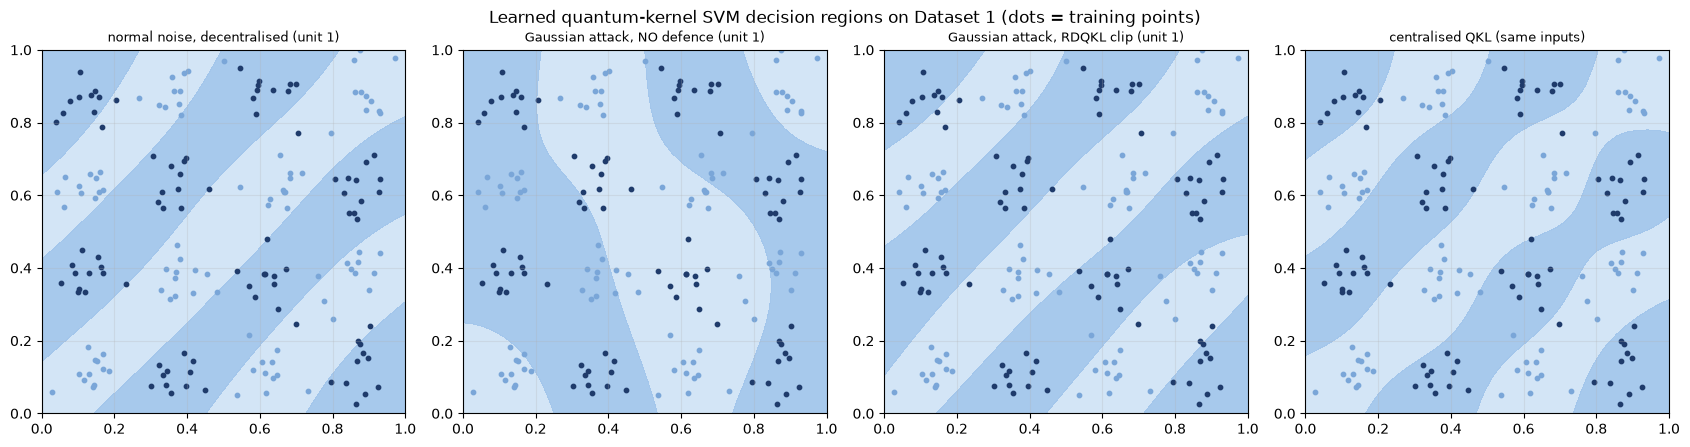

In [23]:
# Figure analogue: decision regions of the learned quantum kernel (one honest unit of the Gaussian-attack runs, with and without the clip)
def decision_map(theta_i, p_i, Xtr, ytr, ax, title, n=36):
    g = np.linspace(0, 1, n); XX, YY = np.meshgrid(g, g); grid = np.c_[XX.ravel(), YY.ravel()]
    Xt, yt = torch.tensor(Xtr), ytr
    with torch.no_grad():
        Ktr = kernel_matrix(Xt, Xt, torch.tensor(theta_i), N_LAYERS, p_i).numpy(); Kg = kernel_matrix(torch.tensor(grid), Xt, torch.tensor(theta_i), N_LAYERS, p_i).numpy()
    clf = SVC(kernel="precomputed", C=SVM_C).fit((Ktr + Ktr.T) / 2, yt)
    ax.contourf(XX, YY, clf.decision_function(Kg).reshape(n, n), levels=[-1e9, 0, 1e9], colors=["#cfe3f6", "#9ec3ea"], alpha=0.9)
    for c, col in ((0, "#7aa6d8"), (1, "#1f3b6b")): ax.scatter(Xtr[ytr == c, 0], Xtr[ytr == c, 1], s=10, c=col)
    ax.set_title(title, fontsize=9); ax.set_aspect("equal")
fig, ax = plt.subplots(1, 4, figsize=(17, 4.3))
r_dn, r_gn, r_gd = res(R1, "dec normal")[0], res(R1, "gauss no-defence")[0], res(R1, "gauss RDQKL")[0]
decision_map(r_dn["theta"][0], P_NORMAL, X1tr, y1tr, ax[0], "normal noise, decentralised (unit 1)")
decision_map(r_gn["theta"][0], P_NORMAL, X1tr, y1tr, ax[1], "Gaussian attack, NO defence (unit 1)")
decision_map(r_gd["theta"][0], P_NORMAL, X1tr, y1tr, ax[2], "Gaussian attack, RDQKL clip (unit 1)")
rc = res(R1, "cen normal")[0]; decision_map(rc["theta"][0], P_NORMAL, X1tr, y1tr, ax[3], "centralised QKL (same inputs)")
plt.suptitle("Learned quantum-kernel SVM decision regions on Dataset 1 (dots = training points)"); plt.tight_layout(); plt.show()

## 9. Verdict, claim by claim

Each numerical entry of Tables I and II is compared with the notebook's value (tolerance 2 accuracy points; with 60 test points a single test sample is already 1.67 points, so this is a strict test, and with one seed some rows move by more than that from run to run). Then the six qualitative claims C1-C6 of the paper are judged from the notebook's own evidence.

In [24]:
# ---------------- verdicts, claim by claim ----------------
TOL = 2.0       # accuracy points; the test set has 60 points, so one point = 1.67
vt = pd.DataFrame(verdict_rows)
vt["verdict"] = np.where(vt["gap (nb - paper)"].abs() <= TOL, "reproduced", np.where(vt["gap (nb - paper)"] < 0, "not reached (%.1f pts below)", "exceeded (%.1f pts above)"))
vt["verdict"] = [v % abs(g) if "%" in v else v for v, g in zip(vt["verdict"], vt["gap (nb - paper)"])]
display(vt)
print("\nNumerical claims reproduced within %.0f accuracy points: %d of %d" % (TOL, (vt.verdict == "reproduced").sum(), len(vt)))

# qualitative claims of the paper
def S3(R, lab): return mean_score(R, lab, 2)[0]
def itr(R, lab, T, budget):
    v = [x for x in iterations_to_target(R, lab, T) if not np.isnan(x)]; return np.mean(v) if v else np.inf
claims = []
for nm, R, T, dit, cit in (("Dataset 1", R1, T1, DS1_ITERS, DS1_ITERS * CEN_FACTOR), ("Dataset 2", R2, T2, DS2_ITERS, DS2_ITERS * CEN_FACTOR)):
    i_dec, i_cen = itr(R, "dec normal", T, dit), itr(R, "cen normal", T, cit)
    claims.append((nm + ": decentralised QKL needs fewer iterations than centralised QKL (paper: 3.7x / 3.0x fewer)",
                   "reproduced" if i_dec < i_cen else "not reached", "decentralised %s vs centralised %s iterations to the alignment target" % ("%d" % i_dec if np.isfinite(i_dec) else "not reached", "%d" % i_cen if np.isfinite(i_cen) else "not reached")))
    d, c = S3(R, "dec normal"), S3(R, "cen normal")
    claims.append((nm + ": decentralised accuracy comparable to / better than centralised (paper: %s)" % ("93.3 vs 98.3" if nm == "Dataset 1" else "88.3 vs 81.7"),
                   "reproduced" if d >= c - TOL else "not reached", "decentralised %.1f vs centralised %.1f" % (d, c)))
    d_hi, d_q = S3(R, "dec rel-high"), S3(R, "dec quite-high")
    claims.append((nm + ": a high-noise unit does not hurt the others (paper: Score3 within a few points of normal)",
                   "reproduced" if min(d_hi, d_q) >= d - 5 else "not reached", "normal %.1f | 0.5%%/0.2%% node-2 noise %.1f | 5%% %.1f" % (d, d_hi, d_q)))
    g_nd, g_rd, s_nd, s_rd = S3(R, "gauss no-defence"), S3(R, "gauss RDQKL"), S3(R, "sign no-defence"), S3(R, "sign RDQKL")
    claims.append((nm + ": Gaussian attack ruins plain decentralised QKL, RDQKL repairs it (paper: ~50% -> 85-98%)",
                   "reproduced" if (g_nd < d - 10 and g_rd >= d - 5) else ("partly (attack effect %.1f pts, repair %.1f pts)" % (d - g_nd, g_rd - g_nd)), "no defence %.1f -> RDQKL %.1f (clean %.1f)" % (g_nd, g_rd, d)))
    claims.append((nm + ": sign-flipping attack hurts plain decentralised QKL, the clip mitigates it (paper: 53.6 -> 88.9 / 82.5 -> 83.9)",
                   "reproduced" if (s_nd < d - 10 and s_rd > s_nd + 5) else "not reproduced: attack too weak here" if s_nd >= d - 5 else "partly", "no defence %.1f -> RDQKL %.1f (clean %.1f)" % (s_nd, s_rd, d)))
a_lo, a_hi = sweep["sweep p=%g" % SWEEP_P[1]]["hist"][-1][1][0], sweep["sweep p=%g" % SWEEP_P[-1]]["hist"][-1][1][0]
claims.append(("Strong noise slows kernel learning (Fig. 3, Eq. 21)", "reproduced" if (a_hi < a_lo and gn[-1][1] < gn[0][1]) else "not reached",
               "final alignment %.4f at p=%.2g%% vs %.4f at p=%.2g%%; gradient norm %.3f -> %.3f" % (a_lo, 100 * SWEEP_P[1], a_hi, 100 * SWEEP_P[-1], gn[0][1], gn[-1][1])))
display(pd.DataFrame(claims, columns=["claim", "verdict", "evidence from this notebook"]))

,table,scenario,metric,paper,notebook,gap (nb - paper),verdict
0,I,Normal noise: decentralised QKL (p=0.05% all),Score1,100.00,96.51,-3.49,not reached (3.5 pts below)
1,I,Normal noise: decentralised QKL (p=0.05% all),Score2,81.67,54.58,-27.09,not reached (27.1 pts below)
2,I,Normal noise: decentralised QKL (p=0.05% all),Score3,93.33,93.33,0.00,reproduced
3,I,Normal noise: centralised QKL,Score3,98.33,95.00,-3.33,not reached (3.3 pts below)
4,I,Normal noise: local QKL,Score1,100.00,96.51,-3.49,not reached (3.5 pts below)
5,I,Normal noise: local QKL,Score2,66.67,57.08,-9.59,not reached (9.6 pts below)
6,I,Normal noise: local QKL,Score3,85.42,88.33,2.91,exceeded (2.9 pts above)
7,I,Relatively high noise on node 2: decentralised,Score1,82.78,95.35,12.57,exceeded (12.6 pts above)
8,I,Relatively high noise on node 2: decentralised,Score2,100.00,55.56,-44.44,not reached (44.4 pts below)
9,I,Relatively high noise on node 2: decentralised,Score3,94.58,90.42,-4.16,not reached (4.2 pts below)



Numerical claims reproduced within 2 accuracy points: 5 of 38


,claim,verdict,evidence from this notebook
0,Dataset 1: decentralised QKL needs fewer itera...,reproduced,decentralised 150 vs centralised 810 iteration...
1,Dataset 1: decentralised accuracy comparable t...,reproduced,decentralised 93.3 vs centralised 95.0
2,Dataset 1: a high-noise unit does not hurt the...,reproduced,normal 93.3 | 0.5%/0.2% node-2 noise 93.3 | 5%...
3,Dataset 1: Gaussian attack ruins plain decentr...,reproduced,no defence 60.0 -> RDQKL 93.3 (clean 93.3)
4,Dataset 1: sign-flipping attack hurts plain de...,not reproduced: attack too weak here,no defence 94.4 -> RDQKL 90.6 (clean 93.3)
5,Dataset 2: decentralised QKL needs fewer itera...,reproduced,decentralised 25 vs centralised 75 iterations ...
6,Dataset 2: decentralised accuracy comparable t...,reproduced,decentralised 91.7 vs centralised 90.0
7,Dataset 2: a high-noise unit does not hurt the...,not reached,normal 91.7 | 0.5%/0.2% node-2 noise 91.7 | 5%...
8,Dataset 2: Gaussian attack ruins plain decentr...,"partly (attack effect 5.0 pts, repair -5.0 pts)",no defence 86.7 -> RDQKL 81.7 (clean 91.7)
9,Dataset 2: sign-flipping attack hurts plain de...,reproduced,no defence 76.7 -> RDQKL 85.6 (clean 91.7)


In [25]:
# Final side-by-side summary (printed in the format used by the other notebooks of this project)
n_ok, n_all = int((vt.verdict == "reproduced").sum()), len(vt)
print("RDQKL (Ma et al., 2025) vs this notebook | FAST_MODE =", FAST_MODE, "| seeds:", SEEDS)
print("-" * 100)
for _, r in vt[vt.metric == "Score3"].iterrows():
    print("%-4s | %-70s | paper %6.2f | notebook %6.2f | %s" % (r.table, r.scenario[:70], r.paper, r.notebook, r.verdict))
print("-" * 100)
print("Score1/Score2/Score3 rows reproduced within %.0f points: %d / %d  (see the table above for each one)" % (TOL, n_ok, n_all))
if FAST_MODE: print("NOTE: FAST_MODE budgets are far too small for the numbers to mean anything; set FAST_MODE = False for the reported run.")

RDQKL (Ma et al., 2025) vs this notebook | FAST_MODE = False | seeds: [42]
----------------------------------------------------------------------------------------------------
I    | Normal noise: decentralised QKL (p=0.05% all)                          | paper  93.33 | notebook  93.33 | reproduced
I    | Normal noise: centralised QKL                                          | paper  98.33 | notebook  95.00 | not reached (3.3 pts below)
I    | Normal noise: local QKL                                                | paper  85.42 | notebook  88.33 | exceeded (2.9 pts above)
I    | Relatively high noise on node 2: decentralised                         | paper  94.58 | notebook  90.42 | not reached (4.2 pts below)
I    | Relatively high noise: centralised                                     | paper  98.33 | notebook  66.67 | not reached (31.7 pts below)
I    | Relatively high noise: local (node 2 only)                             | paper  73.33 | notebook  70.00 | not reached (3.3 pts belo

## 10. Reading the paper critically

1. **Under-specified experiments.** The step size, mini-batch size, initial parameters, dataset sizes, blob width, the classifier on the kernel, the clipping variable and the convergence criterion are not given, and the accuracies of Tables I and II depend on them; with a 60-point test set one error is 1.7 points. Single-run tables without error bars cannot support the digit-level comparisons the paper makes.
2. **The clipping rule as printed does not work as printed.** Clipping $\theta_j$ itself (Eq. 36) bounds the *norm of the parameters*, which would force the 80 angles into a ball of radius 0.5 (or 0.05) around zero for every unit, including the trusted own copy. The text says the own parameters are the reference, so the defence has to act on the *difference* to them (centred clipping), which is what we implemented. The paper's $\tau=0.5$ and $0.05$ are only meaningful for that reading.
3. **The attacks are weak by construction in a small network, and the outcome depends on the exact attack definition.** In this notebook the sign-flipping attacker (it sends $-$mean of its neighbours' parameters) leaves plain decentralised QKL almost untouched on Dataset 1 (Score3 about 94 % against 93 % without attack; the paper reports 53.6 %): after averaging with weight 1/3 it acts as a shrinkage of the neighbours' angles towards zero, and a kernel that already works at small angles survives that. The Gaussian attack (variance pooled over all received entries) is clearly damaging on the ring (60 % against 93 %) but only mildly on the fully connected graph of Dataset 2 (86.7 % against 91.7 %), where the attacker's weight is only 1/4. Whether an attack "ruins" the model therefore depends on the attack's definition, the topology and the size of the network; the paper does not give enough detail to pin these down.
4. **The speed-up is a sample-count effect.** Decentralised QKL with 4 units processes 4 mini-batches per iteration while the centralised baseline processes one, so a 3-4x smaller iteration count is expected for plain SGD on a noisy objective; it says nothing about wall-clock time, communication cost or quantum-resource cost (every unit still evaluates its own kernel entries). The paper counts iterations only.
5. **Noise robustness depends on how the noise is counted.** With a depolarising channel on every qubit after every gate, one kernel evaluation contains 480 channels, so per-gate probabilities of 0.05 %, 0.2 % and 0.5 % correspond to a global depolarisation of 21 %, 62 % and 91 %. At 0.5 % the kernel is almost flat (the fitted slope of the noisy against the ideal kernel is 0.10): a single unit trained alone or a centralised run at that noise level reaches only 67 % here, whereas the paper reports 98.3 % for the centralised run at 0.5 %. Either the paper's noise is applied less often than in our reading (for example once per gate rather than once per wire, which would match its quoted 32.98 % equivalent intensity for a smaller $\tilde p$) or its centralised model is far less sensitive than ours. Decentralisation does help in our runs, because the clean units keep the shared parameters useful, and a 5 % unit has an essentially zero gradient and simply drops out, as the theory says. The paper also assumes infinitely many shots ("we assume that m is large enough"); with a realistic number of shots even the 0.05 % units would be much noisier.
6. **Only 2-D data on 5 qubits.** Two input features give a trivially simple data manifold, and a classical RBF-SVM reaches 96.7 % Score3 on both datasets (see the baseline table), i.e. above every quantum number here and above the paper's. The experiments show that the *protocol* (consensus, clipping) survives noise and attacks; they do not show a quantum advantage or any scaling of the protocol with qubit number, network size or the fraction of malicious units (here 1 of 4).
7. **No privacy analysis.** The decentralised design is motivated by privacy, but exchanging 80 parameters per step leaks information about the local data and the paper does not quantify it.

## 11. Exercises

1. **Step size.** Rerun Dataset 1 with `LR = 1, 2, 8`. For which values does the plain decentralised run converge, and does the speed-up over the centralised run change?
2. **Literal clipping.** Implement Eq. (36) exactly (clip $\theta_j$ itself, not the difference) as a fourth aggregator and compare it with the centred clip under the Gaussian attack. What happens to the norm of the parameters?
3. **Stronger attacker.** Make the attacker send $-10\times$ the average (sign flipping with amplification) or let two of four units be malicious. Which aggregator survives, the clip with $\tau=0.05$ or the coordinate-wise median?
4. **Shot noise.** Replace the exact kernel entries by estimates from `m` shots (binomial sampling with success probability $K_e$, Eq. 15) for `m = 100, 1000, 10000` and repeat the Gaussian-attack experiment. At which `m` do the high-noise units start to matter?
5. **Topology.** Use a line (path) graph with the attacker at the middle node and an attacker at the end node. How does the second-largest eigenvalue of $W$ predict the damage and the iterations to convergence?